# Miniprojeto 2 — Modelagem de Churn com Árvore de Decisão e XGBoost

Este notebook dá sequência ao pré-processamento (`preprocessing.ipynb`) e treina modelos para prever o cancelamento de clientes (*churn*) nos 60 dias seguintes à data-base de 21/09/2026.

**Objetivos da etapa**

- Árvore de Decisão: exploração de hiperparâmetros, pré-poda × pós-poda (`ccp_alpha`), extração de regras SE-ENTÃO e importância dos atributos.
- XGBoost: busca de hiperparâmetros com `GridSearchCV` e Optuna, e análise do trade-off entre `n_estimators` e `learning_rate`.
- Métrica principal: **recall da classe churn**, acompanhado de precisão, F1 e ROC-AUC, com análise de overfitting (gap treino × teste).

**Ordem de execução:** `EDA.ipynb` → `preprocessing.ipynb` → `modeling.ipynb`.

## 1. Bibliotecas e configurações

Fixamos uma semente única (`SEED = 42`), a mesma usada na divisão treino/teste do pré-processamento, para que todos os resultados sejam reproduzíveis.

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

import xgboost
import optuna
import sklearn

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print(f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | optuna {optuna.__version__}")

scikit-learn 1.9.1 | xgboost 3.4.1 | optuna 5.1.0


## 2. Carga dos dados

Utilizamos os arquivos **antes da imputação** exportados pelo pré-processamento, e não os já preparados. O preenchimento de ausentes e a codificação precisam ser reaprendidos dentro de cada rodada da validação cruzada, olhando apenas a parte de treino daquela rodada; usar dados já imputados levaria estatísticas da parte de validação para o ajuste (*data leakage*).

- `id_cliente` é lido como texto e fica fora dos preditores (é só um identificador).
- `churn` é o alvo.
- Contrato e pagamento são lidos como texto para que os ausentes sejam reconhecidos pelo imputador.

In [2]:
DIRETORIO_DADOS = Path("../data/processed")
if not DIRETORIO_DADOS.exists():
    DIRETORIO_DADOS = Path("data/processed")
if not DIRETORIO_DADOS.exists():
    raise FileNotFoundError("Execute antes o preprocessing.ipynb para gerar data/processed/.")

TIPOS_LEITURA = {
    "id_cliente": "string",
    "tipo_contrato": "string",
    "forma_pagamento": "string",
}


def carregar_conjunto(nome):
    dados = pd.read_csv(DIRETORIO_DADOS / nome, dtype=TIPOS_LEITURA)
    X = dados.drop(columns=["id_cliente", "churn"])
    y = dados["churn"].astype(int)
    ids = dados["id_cliente"]
    return X, y, ids


X_treino, y_treino, ids_treino = carregar_conjunto("treino_antes_imputacao.csv")
X_teste, y_teste, ids_teste = carregar_conjunto("teste_antes_imputacao.csv")

print(f"Treino: {X_treino.shape[0]} clientes | Teste (reservado): {X_teste.shape[0]} clientes")
print(f"Preditores ({X_treino.shape[1]}): {list(X_treino.columns)}")

Treino: 3493 clientes | Teste (reservado): 1497 clientes
Preditores (8): ['mensalidade_rs', 'atrasos_6m', 'tipo_contrato', 'forma_pagamento', 'fibra_optica', 'debito_automatico', 'chamados_90d', 'tempo_cliente_meses']


### 2.1 Conferência dos dados

Verificamos o balanceamento do alvo (a estratificação deve manter a mesma proporção de churn nos dois conjuntos), os valores ausentes que o pipeline vai tratar e se nenhum cliente aparece nos dois conjuntos.

In [3]:
assert set(ids_treino).isdisjoint(ids_teste), "Cliente presente no treino e no teste"
assert X_treino.columns.equals(X_teste.columns)

distribuicao = pd.DataFrame({
    "Treino (n)": y_treino.value_counts().sort_index(),
    "Treino (%)": (y_treino.value_counts(normalize=True).sort_index() * 100).round(2),
    "Teste (n)": y_teste.value_counts().sort_index(),
    "Teste (%)": (y_teste.value_counts(normalize=True).sort_index() * 100).round(2),
})
distribuicao.index = ["Não churn (0)", "Churn (1)"]
print("--- DISTRIBUIÇÃO DO ALVO ---")
display(distribuicao)

print("--- VALORES AUSENTES (SERÃO TRATADOS DENTRO DO PIPELINE) ---")
display(pd.DataFrame({"Treino": X_treino.isna().sum(), "Teste": X_teste.isna().sum()}))

PROPORCAO_NEG_POS = (y_treino == 0).sum() / (y_treino == 1).sum()
print(f"Razão negativos/positivos no treino: {PROPORCAO_NEG_POS:.2f}")

--- DISTRIBUIÇÃO DO ALVO ---


,Treino (n),Treino (%),Teste (n),Teste (%)
Não churn (0),2253,64.5,965,64.46
Churn (1),1240,35.5,532,35.54


--- VALORES AUSENTES (SERÃO TRATADOS DENTRO DO PIPELINE) ---


,Treino,Teste
mensalidade_rs,91,41
atrasos_6m,36,7
tipo_contrato,16,9
forma_pagamento,13,7
fibra_optica,0,0
debito_automatico,0,0
chamados_90d,0,0
tempo_cliente_meses,0,0


Razão negativos/positivos no treino: 1.82


## 3. Protocolo anti-vazamento

Todos os modelos seguem as mesmas regras:

1. **Pipeline único.** Cada modelo é encadeado com uma cópia nova (`clone`) do `preprocessador_template.joblib`. Assim, imputação e codificação são ajustadas apenas nos dados de treino de cada rodada.
2. **Validação cruzada estratificada** com 5 partes (`StratifiedKFold`, `shuffle=True`, `random_state=42`), mantendo a proporção de churn em cada parte. Toda escolha de hiperparâmetros e de limiar de decisão é feita aqui.
3. **Teste intocado.** `X_teste`/`y_teste` só são usados na avaliação final, uma única vez, depois de todas as escolhas.

In [4]:
PREPROCESSADOR_TEMPLATE = joblib.load(DIRETORIO_DADOS / "preprocessador_template.joblib")

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def montar_pipeline(modelo):
    """Encadeia uma cópia não ajustada do pré-processamento com o modelo."""
    return Pipeline([
        ("prep", clone(PREPROCESSADOR_TEMPLATE)),
        ("modelo", modelo),
    ])


PREPROCESSADOR_TEMPLATE

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacao', ...), ('transformacao', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('mensalidade', ...), ('atrasos', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. 

### 3.1 Checagem do pré-processamento

Ajustamos o template no treino completo e comparamos com o `treino_preparado.csv` exportado pelo pré-processamento. Os dois precisam ser idênticos, o que confirma que o pipeline usado aqui reproduz a base tratada (entregável 3). Também conferimos que o template carregado está sem ajuste, evitando reaproveitar parâmetros aprendidos fora da validação cruzada.

In [5]:
from sklearn.utils.validation import check_is_fitted
from sklearn.exceptions import NotFittedError

try:
    check_is_fitted(PREPROCESSADOR_TEMPLATE)
    raise AssertionError("O template não deveria estar ajustado")
except NotFittedError:
    pass

prep_conferencia = clone(PREPROCESSADOR_TEMPLATE)
X_treino_conferencia = prep_conferencia.fit_transform(X_treino)

treino_exportado = pd.read_csv(DIRETORIO_DADOS / "treino_preparado.csv", dtype={"id_cliente": "string"})
treino_exportado = treino_exportado.drop(columns=["id_cliente", "churn"])

assert list(X_treino_conferencia.columns) == list(treino_exportado.columns)
np.testing.assert_allclose(
    X_treino_conferencia.to_numpy(dtype=float), treino_exportado.to_numpy(dtype=float)
)

ATRIBUTOS = list(X_treino_conferencia.columns)
print(f"Pipeline reproduz o treino_preparado.csv: {X_treino_conferencia.shape}")
print(f"Atributos após o pré-processamento: {ATRIBUTOS}")
display(X_treino_conferencia.head())

del prep_conferencia, X_treino_conferencia, treino_exportado

Pipeline reproduz o treino_preparado.csv: (3493, 8)
Atributos após o pré-processamento: ['mensalidade_rs', 'atrasos_6m', 'chamados_90d', 'tempo_cliente_meses', 'tipo_contrato', 'forma_pagamento', 'fibra_optica', 'debito_automatico']


,mensalidade_rs,atrasos_6m,chamados_90d,tempo_cliente_meses,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico
0,73.33,0.0,0,21,2.0,1.0,0,1
1,69.40,1.0,1,20,2.0,0.0,0,0
2,98.76,0.0,0,15,0.0,0.0,1,0
3,92.37,0.0,2,24,2.0,2.0,1,1
4,58.78,0.0,2,51,0.0,2.0,0,0


## 4. Estratégia de avaliação

### 4.1 Por que não otimizar apenas o recall

O recall da classe churn é a métrica principal: deixar escapar um cliente que vai cancelar (falso negativo) custa mais do que oferecer retenção a quem ficaria (falso positivo). Porém, **otimizar só o recall é degenerado**: um modelo que diz "todos vão cancelar" tem recall 1,0 e não serve para nada. Por isso adotamos duas etapas:

1. **Busca de hiperparâmetros pela PR-AUC** (`average_precision`, área sob a curva precisão-recall). Ela mede a qualidade da **ordenação** dos clientes por risco em todos os limiares ao mesmo tempo, sem depender do corte de 0,5, e é a medida recomendada para classes desbalanceadas (o modelo trivial tem PR-AUC igual à prevalência, 0,355).
2. **Ajuste do limiar de decisão.** Em vez do corte padrão de 0,5, escolhemos o limiar que atinge um **recall-alvo de 80%** com a maior precisão possível. As probabilidades usadas nessa escolha são *out-of-fold* (cada cliente do treino é previsto por um modelo que não o viu), então o teste continua intocado.

**Métrica oficial de comparação entre modelos: precisão com recall ≥ 80%.** Ela responde à pergunta de negócio: "para encontrar 8 de cada 10 clientes que vão cancelar, quantos alarmes falsos geramos?". Acompanhamos também recall, precisão, F1, F2, ROC-AUC e acurácia, sempre na validação e no treino, para medir o gap de overfitting.

> **Histórico da decisão (investigação da equipe).** O critério de busca passou por três versões. (1) **Recall puro**, usado na primeira versão do notebook de XGBoost: leva a modelos que preveem churn para quase todos (recall 0,90, precisão 0,48). (2) **F2** (β = 2, recall com peso 4): com 35,5% de churn na base, o modelo trivial "sempre churn" já tem F2 = 0,733, e o Optuna encontrou um XGBoost com F2 = 0,774 que apenas deslocava o corte (recall 0,95, precisão 0,45). (3) **PR-AUC + ajuste de limiar**, adotado: separa a qualidade do modelo (ordenação dos clientes por risco) da escolha do ponto de operação (limiar). A seção 6.3.1 mostra que, igualado o recall em 80%, os três objetivos geram modelos de qualidade parecida: **o objetivo da busca mexe principalmente no ponto de corte, não no poder de discriminação**. Por isso é mais limpo decidir as duas coisas separadamente.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, fbeta_score, make_scorer, precision_recall_curve,
    precision_score, recall_score
)
from sklearn.model_selection import GridSearchCV, cross_val_predict, cross_validate
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

F2 = make_scorer(fbeta_score, beta=2)
METRICAS = {
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "f2": F2,
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "accuracy": "accuracy",
}
METRICA_BUSCA = "pr_auc"
RECALL_ALVO = 0.80

RESULTADOS_CV = {}   # métricas médias da validação cruzada por modelo
LIMIARES = {}        # limiar escolhido e métricas out-of-fold por modelo


def _registrar(nome, medias_val, medias_treino, desvio_recall, tempo):
    linha = {}
    for m in METRICAS:
        linha[f"{m} (val)"] = medias_val[m]
        linha[f"{m} (treino)"] = medias_treino[m]
    linha["recall dp (val)"] = desvio_recall
    linha["tempo (s)"] = tempo
    RESULTADOS_CV[nome] = linha


def avaliar_cv(nome, pipeline):
    """Validação cruzada de um pipeline com hiperparâmetros fixos."""
    inicio = time.perf_counter()
    r = cross_validate(
        pipeline, X_treino, y_treino, cv=CV, scoring=METRICAS,
        return_train_score=True, n_jobs=-1
    )
    _registrar(
        nome,
        {m: r[f"test_{m}"].mean() for m in METRICAS},
        {m: r[f"train_{m}"].mean() for m in METRICAS},
        r["test_recall"].std(),
        time.perf_counter() - inicio,
    )


def registrar_busca(nome, busca, tempo):
    """Registra as métricas da melhor combinação de um GridSearchCV."""
    res, i = busca.cv_results_, busca.best_index_
    _registrar(
        nome,
        {m: res[f"mean_test_{m}"][i] for m in METRICAS},
        {m: res[f"mean_train_{m}"][i] for m in METRICAS},
        res["std_test_recall"][i],
        tempo,
    )


def tabela_cv(nomes=None):
    df = pd.DataFrame(RESULTADOS_CV).T.astype(float)
    if nomes is not None:
        df = df.loc[nomes]
    tabela = df[[f"{m} (val)" for m in ["pr_auc", "roc_auc", "recall", "precision", "f1", "f2"]]].copy()
    tabela["gap recall (treino-val)"] = df["recall (treino)"] - df["recall (val)"]
    tabela["gap acurácia (treino-val)"] = df["accuracy (treino)"] - df["accuracy (val)"]
    tabela["tempo (s)"] = df["tempo (s)"]
    return tabela.round(3)

### 4.2 Ajuste do limiar de decisão

A função abaixo gera probabilidades *out-of-fold* no treino, percorre todos os limiares possíveis e escolhe o de **maior precisão entre os que garantem recall ≥ 80%**. O limiar escolhido aqui será o mesmo aplicado no teste, na avaliação final.

In [7]:
def escolher_limiar(nome, pipeline, recall_alvo=RECALL_ALVO, plotar=True):
    proba = cross_val_predict(
        pipeline, X_treino, y_treino, cv=CV, method="predict_proba", n_jobs=-1
    )[:, 1]
    precisao, recall, limiares = precision_recall_curve(y_treino, proba)
    precisao, recall = precisao[:-1], recall[:-1]

    candidatos = np.where(recall >= recall_alvo, precisao, -1)
    limiar = limiares[np.argmax(candidatos)]

    pred = (proba >= limiar).astype(int)
    pred_05 = (proba >= 0.5).astype(int)
    LIMIARES[nome] = {
        "limiar": limiar,
        "recall (limiar)": recall_score(y_treino, pred),
        "precisão (limiar)": precision_score(y_treino, pred),
        "F1 (limiar)": f1_score(y_treino, pred),
        "F2 (limiar)": fbeta_score(y_treino, pred, beta=2),
        "recall (0,5)": recall_score(y_treino, pred_05),
        "precisão (0,5)": precision_score(y_treino, pred_05),
    }

    if plotar:
        fig, eixo = plt.subplots(figsize=(7, 4))
        eixo.plot(limiares, precisao, label="Precisão")
        eixo.plot(limiares, recall, label="Recall")
        eixo.axvline(limiar, color="red", linestyle="--", label=f"Limiar escolhido = {limiar:.3f}")
        eixo.axhline(recall_alvo, color="gray", linestyle=":", label=f"Recall-alvo = {recall_alvo:.0%}")
        eixo.set_xlabel("Limiar de probabilidade")
        eixo.set_title(f"Precisão e recall out-of-fold × limiar — {nome}")
        eixo.legend(loc="lower left")
        plt.tight_layout()
        plt.show()

    return limiar, proba


def tabela_limiares(nomes=None):
    df = pd.DataFrame(LIMIARES).T.astype(float)
    return (df.loc[nomes] if nomes is not None else df).round(3)

### 4.3 Modelos de referência (baselines)

Antes das árvores, medimos três referências com o mesmo protocolo:

- **Sempre "não churn"**: acurácia de ~64,5% e recall zero. Mostra por que acurácia engana em bases desbalanceadas.
- **Sempre "churn"**: recall 1,0 com precisão igual à prevalência (~35,5%). É o modelo degenerado que mostra por que o recall sozinho não serve (e que até o F2 favorece: F2 = 0,733).
- **Regressão logística** (com padronização e `class_weight="balanced"`): referência linear simples. Qualquer árvore precisa superá-la para justificar a complexidade.

In [8]:
avaliar_cv("Dummy: sempre não churn", montar_pipeline(DummyClassifier(strategy="most_frequent")))
avaliar_cv("Dummy: sempre churn", montar_pipeline(DummyClassifier(strategy="constant", constant=1)))
avaliar_cv("Regressão logística", montar_pipeline(Pipeline([
    ("escala", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])))

print("--- BASELINES (MÉDIA DA VALIDAÇÃO CRUZADA, 5 PARTES) ---")
display(tabela_cv())

--- BASELINES (MÉDIA DA VALIDAÇÃO CRUZADA, 5 PARTES) ---


,pr_auc (val),roc_auc (val),recall (val),precision (val),f1 (val),f2 (val),gap recall (treino-val),gap acurácia (treino-val),tempo (s)
Dummy: sempre não churn,0.355,0.500,0.000,0.000,0.000,0.000,0.000,0.000,7.646
Dummy: sempre churn,0.355,0.500,1.000,0.355,0.524,0.733,0.000,-0.000,6.761
Regressão logística,0.670,0.798,0.729,0.583,0.648,0.694,0.006,0.004,6.944


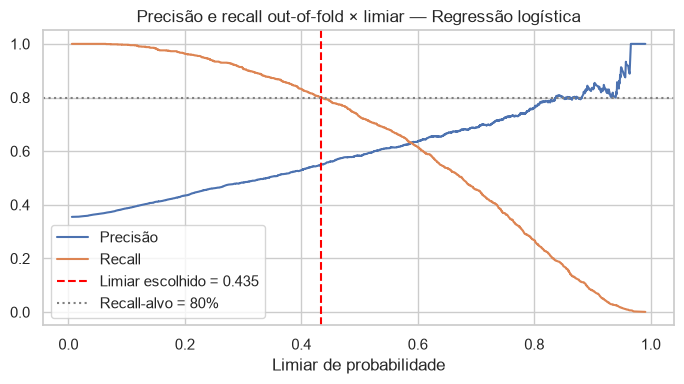

,limiar,recall (limiar),precisão (limiar),F1 (limiar),F2 (limiar),"recall (0,5)","precisão (0,5)"
Regressão logística,0.435,0.801,0.55,0.652,0.734,0.729,0.583


In [9]:
LIMIAR_LR, _ = escolher_limiar("Regressão logística", montar_pipeline(Pipeline([
    ("escala", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])))
display(tabela_limiares())

## 5. Módulo 1 — Árvore de Decisão

Seguimos quatro etapas: (5.1) árvore sem restrições, para observar o overfitting; (5.2) **pré-poda**, limitando o crescimento durante o treino; (5.3) **pós-poda** por complexidade de custo (`ccp_alpha`), podando uma árvore completa; e (5.4) comparação entre as abordagens. Depois extraímos as regras (5.5) e a importância dos atributos (5.6).

### 5.1 Árvore sem restrições

Sem limites, a árvore cresce até isolar cada cliente do treino. Esperamos desempenho quase perfeito no treino e bem pior na validação: é a memorização de ruído que a poda deve corrigir.

In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

avaliar_cv("AD sem restrições", montar_pipeline(DecisionTreeClassifier(random_state=SEED)))

ad_livre = montar_pipeline(DecisionTreeClassifier(random_state=SEED)).fit(X_treino, y_treino)
print(f"Profundidade: {ad_livre[-1].get_depth()} | Folhas: {ad_livre[-1].get_n_leaves()}")
display(tabela_cv(["Regressão logística", "AD sem restrições"]))

Profundidade: 25 | Folhas: 932


,pr_auc (val),roc_auc (val),recall (val),precision (val),f1 (val),f2 (val),gap recall (treino-val),gap acurácia (treino-val),tempo (s)
Regressão logística,0.670,0.798,0.729,0.583,0.648,0.694,0.006,0.004,6.944
AD sem restrições,0.427,0.611,0.492,0.501,0.496,0.494,0.507,0.354,0.497


### 5.2 Pré-poda (parada antecipada)

A busca é feita em **duas etapas** com `GridSearchCV` (5 partes, critério de escolha PR-AUC), para explorar mais hiperparâmetros sem uma grade combinatória gigante.

**Etapa A: hiperparâmetros estruturais.** Justificativa das faixas: o treino tem 3.493 clientes, com cerca de 2.800 em cada rodada da validação.

| Hiperparâmetro | Valores | Justificativa |
|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6, 8, 10, None | Com 8 atributos, profundidades acima de ~10 já isolam grupos minúsculos; 2–4 favorecem regras legíveis. |
| `min_samples_leaf` | 1, 5, 10, 20, 50, 100 | Folhas com ≥ 20 clientes (~0,7% do treino) dão taxas de churn estáveis; 100 testa um regime bem conservador. |
| `min_samples_split` | 2, 20, 50 | Impede divisões de nós pequenos. |
| `criterion` | gini, entropy | As duas medidas de impureza clássicas (`log_loss` equivale a `entropy` no sklearn). |
| `class_weight` | None, balanced | Hiperparâmetro extra: `balanced` dá aos churners peso ~1,8× maior que aos não churners e desloca as divisões a favor do recall. |

**Etapa B: refinamento.** Fixamos o melhor da etapa A e testamos os demais hiperparâmetros do enunciado e outros extras: `max_leaf_nodes`, `min_impurity_decrease`, `max_features` e `splitter`. Os valores padrão estão incluídos na grade, então a etapa B nunca piora o resultado da etapa A.

In [11]:
grade_pre_a = {
    "modelo__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 50, 100],
    "modelo__min_samples_split": [2, 20, 50],
    "modelo__criterion": ["gini", "entropy"],
    "modelo__class_weight": [None, "balanced"],
}

busca_pre_a = GridSearchCV(
    montar_pipeline(DecisionTreeClassifier(random_state=SEED)),
    grade_pre_a, scoring=METRICAS, refit=METRICA_BUSCA, cv=CV,
    n_jobs=-1, return_train_score=True
)
inicio = time.perf_counter()
busca_pre_a.fit(X_treino, y_treino)
tempo_pre_a = time.perf_counter() - inicio

n_comb_a = len(busca_pre_a.cv_results_["params"])
print(f"Etapa A: {n_comb_a} combinações × 5 partes = {n_comb_a * 5} ajustes em {tempo_pre_a:.1f} s")
print(f"Melhor PR-AUC (val): {busca_pre_a.best_score_:.4f}")
print("Melhores hiperparâmetros:", {k.replace("modelo__", ""): v for k, v in busca_pre_a.best_params_.items()})


def top_combinacoes(busca, n=10):
    res = pd.DataFrame(busca.cv_results_)
    colunas = [c for c in res.columns if c.startswith("param_")]
    tabela = res[colunas + [f"mean_test_{METRICA_BUSCA}", "mean_test_f2", "mean_test_recall",
                            "mean_test_precision", f"mean_train_{METRICA_BUSCA}", f"rank_test_{METRICA_BUSCA}"]]
    tabela = tabela.rename(columns=lambda c: c.replace("param_modelo__", ""))
    return tabela.sort_values(f"rank_test_{METRICA_BUSCA}").head(n).round(4)


display(top_combinacoes(busca_pre_a))

Etapa A: 576 combinações × 5 partes = 2880 ajustes em 94.0 s
Melhor PR-AUC (val): 0.6176
Melhores hiperparâmetros: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 50, 'min_samples_split': 2}


,class_weight,criterion,max_depth,min_samples_leaf,min_samples_split,mean_test_pr_auc,mean_test_f2,mean_test_recall,mean_test_precision,mean_train_pr_auc,rank_test_pr_auc
552,balanced,entropy,10,50,2,0.6176,0.6797,0.7218,0.5528,0.6686,1
553,balanced,entropy,10,50,20,0.6176,0.6797,0.7218,0.5528,0.6686,1
554,balanced,entropy,10,50,50,0.6176,0.6797,0.7218,0.5528,0.6686,1
534,balanced,entropy,8,50,2,0.6176,0.6797,0.7218,0.5528,0.6686,1
535,balanced,entropy,8,50,20,0.6176,0.6797,0.7218,0.5528,0.6686,1
536,balanced,entropy,8,50,50,0.6176,0.6797,0.7218,0.5528,0.6686,1
572,balanced,entropy,None,50,50,0.6176,0.6797,0.7218,0.5528,0.6686,1
571,balanced,entropy,None,50,20,0.6176,0.6797,0.7218,0.5528,0.6686,1
570,balanced,entropy,None,50,2,0.6176,0.6797,0.7218,0.5528,0.6686,1
409,balanced,gini,10,50,20,0.6167,0.6751,0.7202,0.5422,0.6693,10


In [12]:
melhores_a = busca_pre_a.best_params_

grade_pre_b = {
    **{k: [v] for k, v in melhores_a.items()},
    "modelo__max_leaf_nodes": [None, 8, 12, 16, 24, 32, 48, 64],
    "modelo__min_impurity_decrease": [0.0, 1e-4, 5e-4, 1e-3, 5e-3],
    "modelo__max_features": [None, "sqrt", 0.75],
    "modelo__splitter": ["best", "random"],
}

busca_pre_b = GridSearchCV(
    montar_pipeline(DecisionTreeClassifier(random_state=SEED)),
    grade_pre_b, scoring=METRICAS, refit=METRICA_BUSCA, cv=CV,
    n_jobs=-1, return_train_score=True
)
inicio = time.perf_counter()
busca_pre_b.fit(X_treino, y_treino)
tempo_pre_b = time.perf_counter() - inicio

n_comb_b = len(busca_pre_b.cv_results_["params"])
print(f"Etapa B: {n_comb_b} combinações × 5 partes = {n_comb_b * 5} ajustes em {tempo_pre_b:.1f} s")
print(f"Melhor PR-AUC (val): {busca_pre_b.best_score_:.4f}  (etapa A: {busca_pre_a.best_score_:.4f})")
print("Melhores hiperparâmetros:", {k.replace("modelo__", ""): v for k, v in busca_pre_b.best_params_.items()})
display(top_combinacoes(busca_pre_b))

registrar_busca("AD pré-poda", busca_pre_b, tempo_pre_a + tempo_pre_b)
ad_pre = busca_pre_b.best_estimator_
print(f"Árvore pré-podada (ajustada no treino completo): profundidade {ad_pre[-1].get_depth()}, "
      f"{ad_pre[-1].get_n_leaves()} folhas")

Etapa B: 240 combinações × 5 partes = 1200 ajustes em 32.6 s
Melhor PR-AUC (val): 0.6176  (etapa A: 0.6176)
Melhores hiperparâmetros: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 8, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 50, 'min_samples_split': 2, 'splitter': 'best'}


,class_weight,criterion,max_depth,max_features,max_leaf_nodes,min_impurity_decrease,min_samples_leaf,min_samples_split,splitter,mean_test_pr_auc,mean_test_f2,mean_test_recall,mean_test_precision,mean_train_pr_auc,rank_test_pr_auc
0,balanced,entropy,8,None,None,0.0000,50,2,best,0.6176,0.6797,0.7218,0.5528,0.6686,1
60,balanced,entropy,8,None,48,0.0000,50,2,best,0.6176,0.6797,0.7218,0.5528,0.6686,2
70,balanced,entropy,8,None,64,0.0000,50,2,best,0.6176,0.6797,0.7218,0.5528,0.6686,2
2,balanced,entropy,8,None,None,0.0001,50,2,best,0.6175,0.6830,0.7266,0.5518,0.6686,4
72,balanced,entropy,8,None,64,0.0001,50,2,best,0.6175,0.6830,0.7266,0.5518,0.6686,5
62,balanced,entropy,8,None,48,0.0001,50,2,best,0.6175,0.6830,0.7266,0.5518,0.6686,5
160,balanced,entropy,8,0.75,None,0.0000,50,2,best,0.6173,0.6915,0.7452,0.5370,0.6617,7
162,balanced,entropy,8,0.75,None,0.0001,50,2,best,0.6165,0.6915,0.7452,0.5370,0.6612,8
4,balanced,entropy,8,None,None,0.0005,50,2,best,0.6162,0.6883,0.7347,0.5503,0.6653,9
74,balanced,entropy,8,None,64,0.0005,50,2,best,0.6162,0.6883,0.7347,0.5503,0.6653,10


Árvore pré-podada (ajustada no treino completo): profundidade 8, 52 folhas


#### 5.2.1 Curva de validação da profundidade

Variamos apenas `max_depth`, mantendo `criterion` e `class_weight` escolhidos e os demais parâmetros no padrão, para isolar o efeito da profundidade. O ponto em que as curvas de treino e validação se afastam é onde a árvore começa a memorizar ruído.

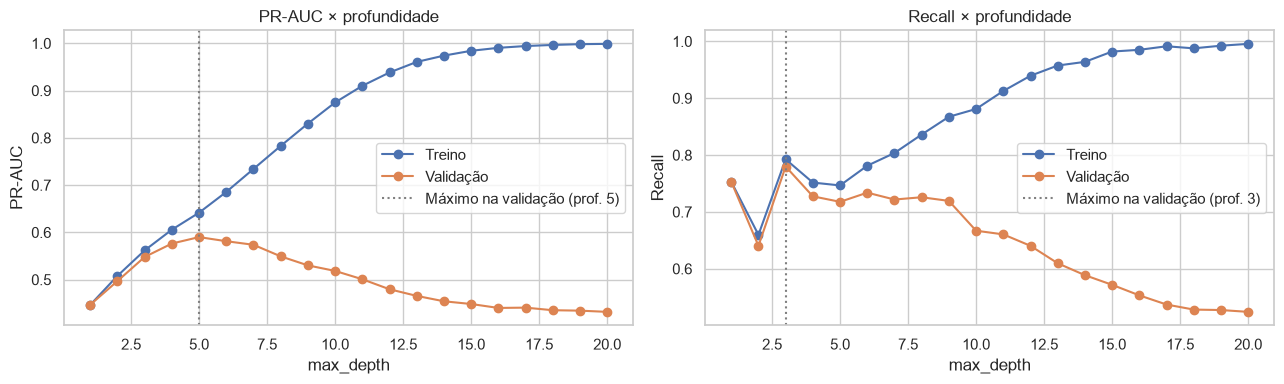

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
PR-AUC treino,0.447,0.508,0.562,0.606,0.642,0.686,0.734,0.783,0.830,0.875,0.910,0.938,0.961,0.974,0.984,0.990,0.994,0.997,0.998,0.999
PR-AUC validação,0.447,0.497,0.548,0.576,0.590,0.581,0.574,0.549,0.530,0.518,0.501,0.480,0.466,0.454,0.448,0.440,0.441,0.435,0.434,0.432
Recall treino,0.753,0.660,0.793,0.752,0.747,0.781,0.804,0.836,0.867,0.881,0.913,0.940,0.957,0.964,0.982,0.985,0.991,0.988,0.992,0.996
Recall validação,0.753,0.640,0.780,0.727,0.718,0.734,0.722,0.726,0.719,0.667,0.660,0.640,0.610,0.589,0.572,0.553,0.537,0.528,0.527,0.524


In [13]:
profundidades = list(range(1, 21))
curva = []
for prof in profundidades:
    modelo = DecisionTreeClassifier(
        max_depth=prof, random_state=SEED,
        criterion=melhores_a["modelo__criterion"],
        class_weight=melhores_a["modelo__class_weight"],
    )
    r = cross_validate(montar_pipeline(modelo), X_treino, y_treino, cv=CV,
                       scoring={"pr_auc": "average_precision", "recall": "recall"}, return_train_score=True, n_jobs=-1)
    curva.append({
        "max_depth": prof,
        "PR-AUC treino": r["train_pr_auc"].mean(), "PR-AUC validação": r["test_pr_auc"].mean(),
        "Recall treino": r["train_recall"].mean(), "Recall validação": r["test_recall"].mean(),
    })
curva = pd.DataFrame(curva).set_index("max_depth")

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for eixo, metrica in zip(eixos, ["PR-AUC", "Recall"]):
    eixo.plot(curva.index, curva[f"{metrica} treino"], marker="o", label="Treino")
    eixo.plot(curva.index, curva[f"{metrica} validação"], marker="o", label="Validação")
    eixo.axvline(curva[f"{metrica} validação"].idxmax(), color="gray", linestyle=":",
                 label=f"Máximo na validação (prof. {curva[f'{metrica} validação'].idxmax()})")
    eixo.set_xlabel("max_depth")
    eixo.set_ylabel(metrica)
    eixo.set_title(f"{metrica} × profundidade")
    eixo.legend()
plt.tight_layout()
plt.show()
display(curva.round(3).T)

### 5.3 Pós-poda por complexidade de custo (`ccp_alpha`)

A pós-poda cresce a árvore completa e depois remove os ramos que menos reduzem a impureza em relação ao número de folhas que acrescentam. O parâmetro `ccp_alpha` controla essa troca: quanto maior, mais agressiva a poda.

1. Calculamos o caminho de poda (`cost_complexity_pruning_path`) da árvore completa, com o mesmo `criterion` e `class_weight` da pré-poda para uma comparação justa. Esse caminho fornece os valores de alpha em que a árvore muda.
2. Esse caminho só define a **lista de candidatos** de alpha. A escolha do alpha é feita por validação cruzada, com o pré-processamento e a árvore reajustados em cada rodada.

Alphas distintos no caminho de poda: 456 | candidatos avaliados: 50


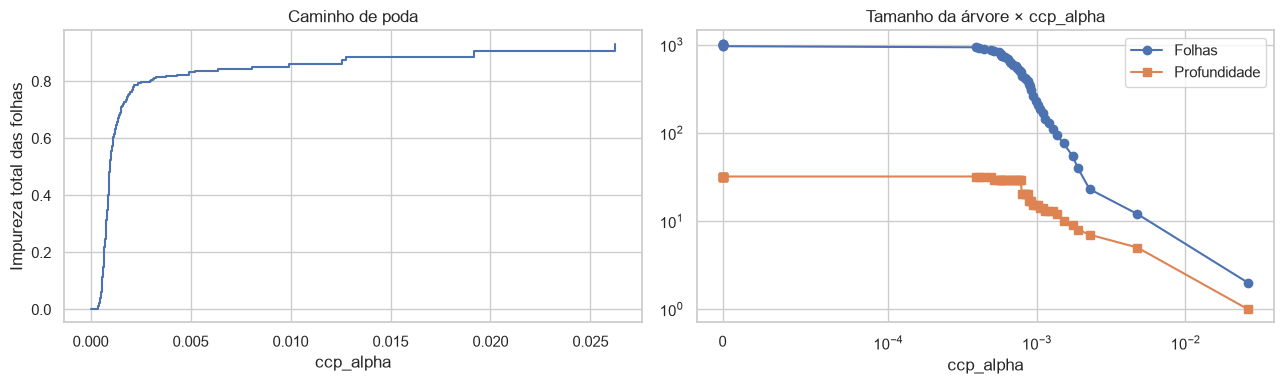

In [14]:
modelo_base_pos = DecisionTreeClassifier(
    random_state=SEED,
    criterion=melhores_a["modelo__criterion"],
    class_weight=melhores_a["modelo__class_weight"],
)

prep_caminho = clone(PREPROCESSADOR_TEMPLATE).fit(X_treino)
caminho = clone(modelo_base_pos).cost_complexity_pruning_path(prep_caminho.transform(X_treino), y_treino)
alphas_caminho, impurezas = caminho.ccp_alphas, caminho.impurities

# Remove o último alpha (árvore só com a raiz) e amostra 50 candidatos por quantis
alphas_candidatos = np.unique(np.quantile(alphas_caminho[:-1], np.linspace(0, 1, 50)))
print(f"Alphas distintos no caminho de poda: {len(alphas_caminho)} | candidatos avaliados: {len(alphas_candidatos)}")

# Estrutura da árvore para cada alpha (descritivo, no treino completo)
estrutura = []
Xp_caminho = prep_caminho.transform(X_treino)
for alpha in alphas_candidatos:
    arv = clone(modelo_base_pos).set_params(ccp_alpha=alpha).fit(Xp_caminho, y_treino)
    estrutura.append({"ccp_alpha": alpha, "folhas": arv.get_n_leaves(), "profundidade": arv.get_depth()})
estrutura = pd.DataFrame(estrutura)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].plot(alphas_caminho[:-1], impurezas[:-1], drawstyle="steps-post")
eixos[0].set_xlabel("ccp_alpha")
eixos[0].set_ylabel("Impureza total das folhas")
eixos[0].set_title("Caminho de poda")
eixos[1].plot(estrutura["ccp_alpha"], estrutura["folhas"], marker="o", label="Folhas")
eixos[1].plot(estrutura["ccp_alpha"], estrutura["profundidade"], marker="s", label="Profundidade")
eixos[1].set_xscale("symlog", linthresh=1e-4)
eixos[1].set_yscale("log")
eixos[1].set_xlabel("ccp_alpha")
eixos[1].set_title("Tamanho da árvore × ccp_alpha")
eixos[1].legend()
plt.tight_layout()
plt.show()

Busca de ccp_alpha: 50 valores em 6.3 s
ccp_alpha escolhido: 0.002264 | PR-AUC (val): 0.5778
Árvore pós-podada: profundidade 7, 23 folhas


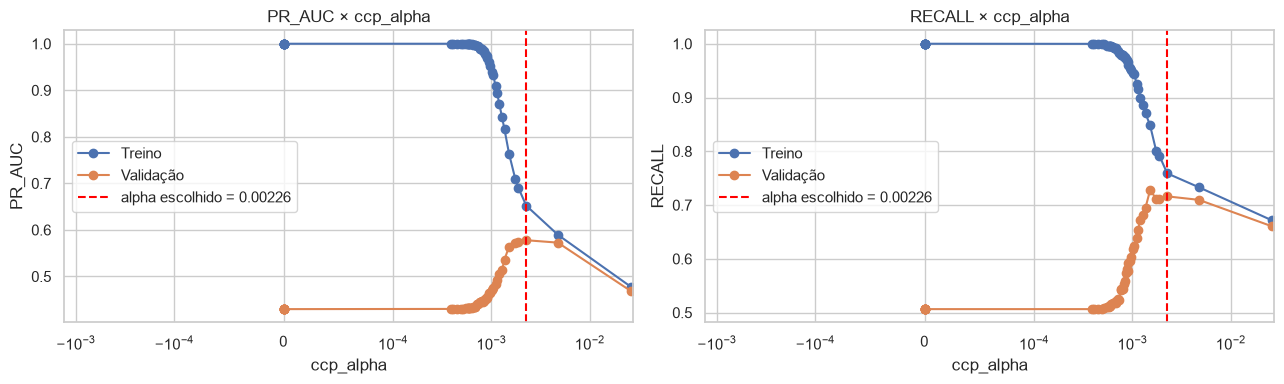

In [15]:
busca_pos = GridSearchCV(
    montar_pipeline(modelo_base_pos),
    {"modelo__ccp_alpha": alphas_candidatos},
    scoring=METRICAS, refit=METRICA_BUSCA, cv=CV, n_jobs=-1, return_train_score=True
)
inicio = time.perf_counter()
busca_pos.fit(X_treino, y_treino)
tempo_pos = time.perf_counter() - inicio

registrar_busca("AD pós-poda", busca_pos, tempo_pos)
ad_pos = busca_pos.best_estimator_
alpha_escolhido = busca_pos.best_params_["modelo__ccp_alpha"]

print(f"Busca de ccp_alpha: {len(alphas_candidatos)} valores em {tempo_pos:.1f} s")
print(f"ccp_alpha escolhido: {alpha_escolhido:.6f} | PR-AUC (val): {busca_pos.best_score_:.4f}")
print(f"Árvore pós-podada: profundidade {ad_pos[-1].get_depth()}, {ad_pos[-1].get_n_leaves()} folhas")

res_pos = pd.DataFrame(busca_pos.cv_results_)
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for eixo, metrica in zip(eixos, ["pr_auc", "recall"]):
    eixo.plot(res_pos["param_modelo__ccp_alpha"].astype(float), res_pos[f"mean_train_{metrica}"], marker="o", label="Treino")
    eixo.plot(res_pos["param_modelo__ccp_alpha"].astype(float), res_pos[f"mean_test_{metrica}"], marker="o", label="Validação")
    eixo.axvline(alpha_escolhido, color="red", linestyle="--", label=f"alpha escolhido = {alpha_escolhido:.5f}")
    eixo.set_xscale("symlog", linthresh=1e-4)
    eixo.set_xlabel("ccp_alpha")
    eixo.set_ylabel(metrica.upper())
    eixo.set_title(f"{metrica.upper()} × ccp_alpha")
    eixo.legend()
plt.tight_layout()
plt.show()

### 5.4 Comparação: sem poda × pré-poda × pós-poda

Comparamos as três árvores pelas métricas médias da validação cruzada, pelo gap treino-validação, pelo tamanho e pelo tempo de busca. Para as duas árvores podadas, também aplicamos o ajuste de limiar (recall-alvo de 80%).

**Critério de escolha da árvore final:** maior PR-AUC na validação; se a diferença for menor que 0,005, preferimos a árvore com menos folhas (mais simples e interpretável).

--- COMPARAÇÃO DAS ÁRVORES (VALIDAÇÃO CRUZADA) ---


,pr_auc (val),roc_auc (val),recall (val),precision (val),f1 (val),f2 (val),gap recall (treino-val),gap acurácia (treino-val),tempo (s),profundidade,folhas
Regressão logística,0.670,0.798,0.729,0.583,0.648,0.694,0.006,0.004,6.944,NaN,NaN
AD sem restrições,0.427,0.611,0.492,0.501,0.496,0.494,0.507,0.354,0.497,25.0,932.0
AD pré-poda,0.618,0.765,0.722,0.553,0.626,0.680,0.033,0.024,126.625,8.0,52.0
AD pós-poda,0.578,0.749,0.716,0.548,0.617,0.671,0.043,0.033,6.286,7.0,23.0


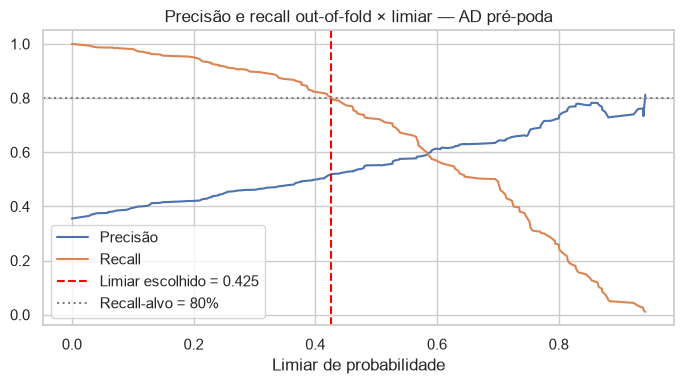

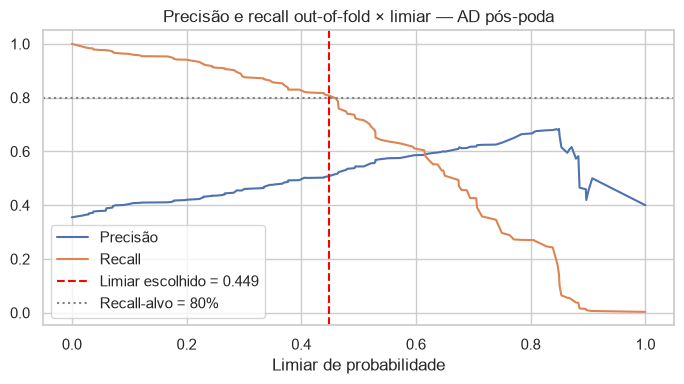

--- AJUSTE DE LIMIAR (OUT-OF-FOLD NO TREINO) ---


,limiar,recall (limiar),precisão (limiar),F1 (limiar),F2 (limiar),"recall (0,5)","precisão (0,5)"
Regressão logística,0.435,0.801,0.550,0.652,0.734,0.729,0.583
AD pré-poda,0.425,0.805,0.518,0.630,0.725,0.722,0.552
AD pós-poda,0.449,0.807,0.508,0.624,0.722,0.716,0.544


In [16]:
nomes_ad = ["AD sem restrições", "AD pré-poda", "AD pós-poda"]
comparacao_ad = tabela_cv(["Regressão logística"] + nomes_ad)
comparacao_ad["profundidade"] = [np.nan, ad_livre[-1].get_depth(), ad_pre[-1].get_depth(), ad_pos[-1].get_depth()]
comparacao_ad["folhas"] = [np.nan, ad_livre[-1].get_n_leaves(), ad_pre[-1].get_n_leaves(), ad_pos[-1].get_n_leaves()]
print("--- COMPARAÇÃO DAS ÁRVORES (VALIDAÇÃO CRUZADA) ---")
display(comparacao_ad)

LIMIAR_AD_PRE, _ = escolher_limiar("AD pré-poda", clone(ad_pre))
LIMIAR_AD_POS, _ = escolher_limiar("AD pós-poda", clone(ad_pos))
print("--- AJUSTE DE LIMIAR (OUT-OF-FOLD NO TREINO) ---")
display(tabela_limiares(["Regressão logística", "AD pré-poda", "AD pós-poda"]))

In [17]:
nota_pre = RESULTADOS_CV["AD pré-poda"][f"{METRICA_BUSCA} (val)"]
nota_pos = RESULTADOS_CV["AD pós-poda"][f"{METRICA_BUSCA} (val)"]

if abs(nota_pre - nota_pos) < 0.005:
    usar_pre = ad_pre[-1].get_n_leaves() <= ad_pos[-1].get_n_leaves()
    motivo = "PR-AUC equivalente; escolhida a árvore com menos folhas"
else:
    usar_pre = nota_pre > nota_pos
    motivo = "maior PR-AUC na validação"

NOME_AD_FINAL = "AD pré-poda" if usar_pre else "AD pós-poda"
AD_FINAL = ad_pre if usar_pre else ad_pos
LIMIAR_AD = LIMIAR_AD_PRE if usar_pre else LIMIAR_AD_POS

print(f"Árvore final: {NOME_AD_FINAL} ({motivo})")
print(f"PR-AUC val — pré: {nota_pre:.4f} | pós: {nota_pos:.4f}")
print(f"Profundidade {AD_FINAL[-1].get_depth()}, {AD_FINAL[-1].get_n_leaves()} folhas, limiar = {LIMIAR_AD:.3f}")

Árvore final: AD pré-poda (maior PR-AUC na validação)
PR-AUC val — pré: 0.6176 | pós: 0.5778
Profundidade 8, 52 folhas, limiar = 0.425


### 5.5 Extração de regras SE-ENTÃO

A árvore final já está ajustada no treino completo. Como o pré-processamento manteve as variáveis na escala original e codificou as categorias de forma ordinal, as condições são traduzidas direto para a linguagem do negócio:

- `tipo_contrato <= 0,5` vira `tipo_contrato ∈ {AUSENTE, MENSAL}`;
- `fibra_optica <= 0,5` vira `fibra_optica = 0`;
- `chamados_90d <= 2,5` vira `chamados_90d <= 2`, porque o atributo é inteiro;
- condições repetidas sobre o mesmo atributo ao longo do caminho são unidas em um único intervalo.

Para cada regra, informamos o **suporte** (quantos clientes do treino ela cobre) e a **taxa de churn real** desses clientes. A previsão da regra é a classe majoritária do nó, ponderada por `class_weight` quando ele é usado.

In [18]:
from sklearn.tree import export_text

CODIGOS = {
    "tipo_contrato": {-1: "AUSENTE", 0: "MENSAL", 1: "ANUAL", 2: "BIENAL"},
    "forma_pagamento": {-1: "AUSENTE", 0: "BOLETO", 1: "CARTAO", 2: "PIX"},
}
BINARIAS = {"fibra_optica", "debito_automatico"}
INTEIRAS = {"atrasos_6m", "chamados_90d", "tempo_cliente_meses"}


def descrever_intervalo(atributo, minimo, maximo):
    """Traduz o intervalo (minimo, maximo] acumulado no caminho para linguagem de negócio."""
    if atributo in CODIGOS:
        categorias = [nome for cod, nome in CODIGOS[atributo].items() if minimo < cod <= maximo]
        return f"{atributo} ∈ {{{', '.join(categorias)}}}"
    if atributo in BINARIAS:
        return f"{atributo} = {1 if minimo >= 0 else 0}"
    if atributo in INTEIRAS:
        de = int(np.floor(minimo)) + 1 if np.isfinite(minimo) else None
        ate = int(np.floor(maximo)) if np.isfinite(maximo) else None
        if de is not None and ate is not None:
            return f"{atributo} = {de}" if de == ate else f"{de} <= {atributo} <= {ate}"
        return f"{atributo} >= {de}" if de is not None else f"{atributo} <= {ate}"
    partes = []
    if np.isfinite(minimo):
        partes.append(f"> R$ {minimo:.2f}")
    if np.isfinite(maximo):
        partes.append(f"<= R$ {maximo:.2f}")
    return f"{atributo} " + " e ".join(partes)


def extrair_regras(pipeline, X, y, profundidade_max=None):
    """Percorre a árvore até `profundidade_max` e mede suporte e churn real de cada regra.

    As condições sobre um mesmo atributo são unidas em um único intervalo
    (ex.: chamados >= 2 E chamados >= 3  →  chamados >= 3).
    """
    arvore = pipeline.named_steps["modelo"].tree_
    Xp = pipeline.named_steps["prep"].transform(X)
    nomes, valores, alvo = list(Xp.columns), Xp.to_numpy(dtype=float), y.to_numpy()
    regras = []

    def visitar(no, mascara, limites, profundidade):
        folha = arvore.children_left[no] == -1
        if folha or profundidade == profundidade_max:
            n = int(mascara.sum())
            condicoes = [descrever_intervalo(a, lo, hi) for a, (lo, hi) in limites.items()]
            regras.append({
                "regra": "SE " + " E ".join(condicoes),
                "previsão": "CHURN" if np.argmax(arvore.value[no][0]) == 1 else "NÃO CHURN",
                "clientes": n,
                "suporte (%)": 100 * n / len(alvo),
                "churn real (%)": 100 * alvo[mascara].mean() if n else np.nan,
            })
            return
        j, t = arvore.feature[no], arvore.threshold[no]
        atributo = nomes[j]
        lo, hi = limites.get(atributo, (-np.inf, np.inf))
        vai_esquerda = valores[:, j] <= t
        visitar(arvore.children_left[no], mascara & vai_esquerda,
                {**limites, atributo: (lo, min(hi, t))}, profundidade + 1)
        visitar(arvore.children_right[no], mascara & ~vai_esquerda,
                {**limites, atributo: (max(lo, t), hi)}, profundidade + 1)

    visitar(0, np.ones(len(alvo), dtype=bool), {}, 0)
    return (pd.DataFrame(regras)
            .sort_values("churn real (%)", ascending=False)
            .reset_index(drop=True)
            .round(1))


def imprimir_regras(regras):
    for _, r in regras.iterrows():
        print(f"{r['regra']}\n    ENTÃO {r['previsão']}  "
              f"[{r['clientes']} clientes, {r['suporte (%)']}% do treino, churn real {r['churn real (%)']}%]\n")


PROFUNDIDADE_REGRAS = 3
regras_topo = extrair_regras(AD_FINAL, X_treino, y_treino, profundidade_max=PROFUNDIDADE_REGRAS)
print(f"--- REGRAS DO TOPO DA ÁRVORE (ATÉ PROFUNDIDADE {PROFUNDIDADE_REGRAS}) — {NOME_AD_FINAL} ---")
print(f"Taxa de churn geral no treino: {100 * y_treino.mean():.1f}%\n")
imprimir_regras(regras_topo)

--- REGRAS DO TOPO DA ÁRVORE (ATÉ PROFUNDIDADE 3) — AD pré-poda ---
Taxa de churn geral no treino: 35.5%

SE tipo_contrato ∈ {AUSENTE, MENSAL} E tempo_cliente_meses <= 28 E chamados_90d >= 3
    ENTÃO CHURN  [349 clientes, 10.0% do treino, churn real 74.5%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E tempo_cliente_meses <= 28 E chamados_90d <= 2
    ENTÃO CHURN  [932 clientes, 26.7% do treino, churn real 50.0%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E tempo_cliente_meses >= 29 E chamados_90d >= 2
    ENTÃO CHURN  [278 clientes, 8.0% do treino, churn real 44.6%]

SE tipo_contrato ∈ {ANUAL, BIENAL} E tempo_cliente_meses <= 22 E fibra_optica = 1
    ENTÃO CHURN  [462 clientes, 13.2% do treino, churn real 37.9%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E tempo_cliente_meses >= 29 E chamados_90d <= 1
    ENTÃO NÃO CHURN  [401 clientes, 11.5% do treino, churn real 20.9%]

SE tipo_contrato ∈ {ANUAL, BIENAL} E tempo_cliente_meses <= 22 E fibra_optica = 0
    ENTÃO NÃO CHURN  [373 clientes, 10.7% do tr

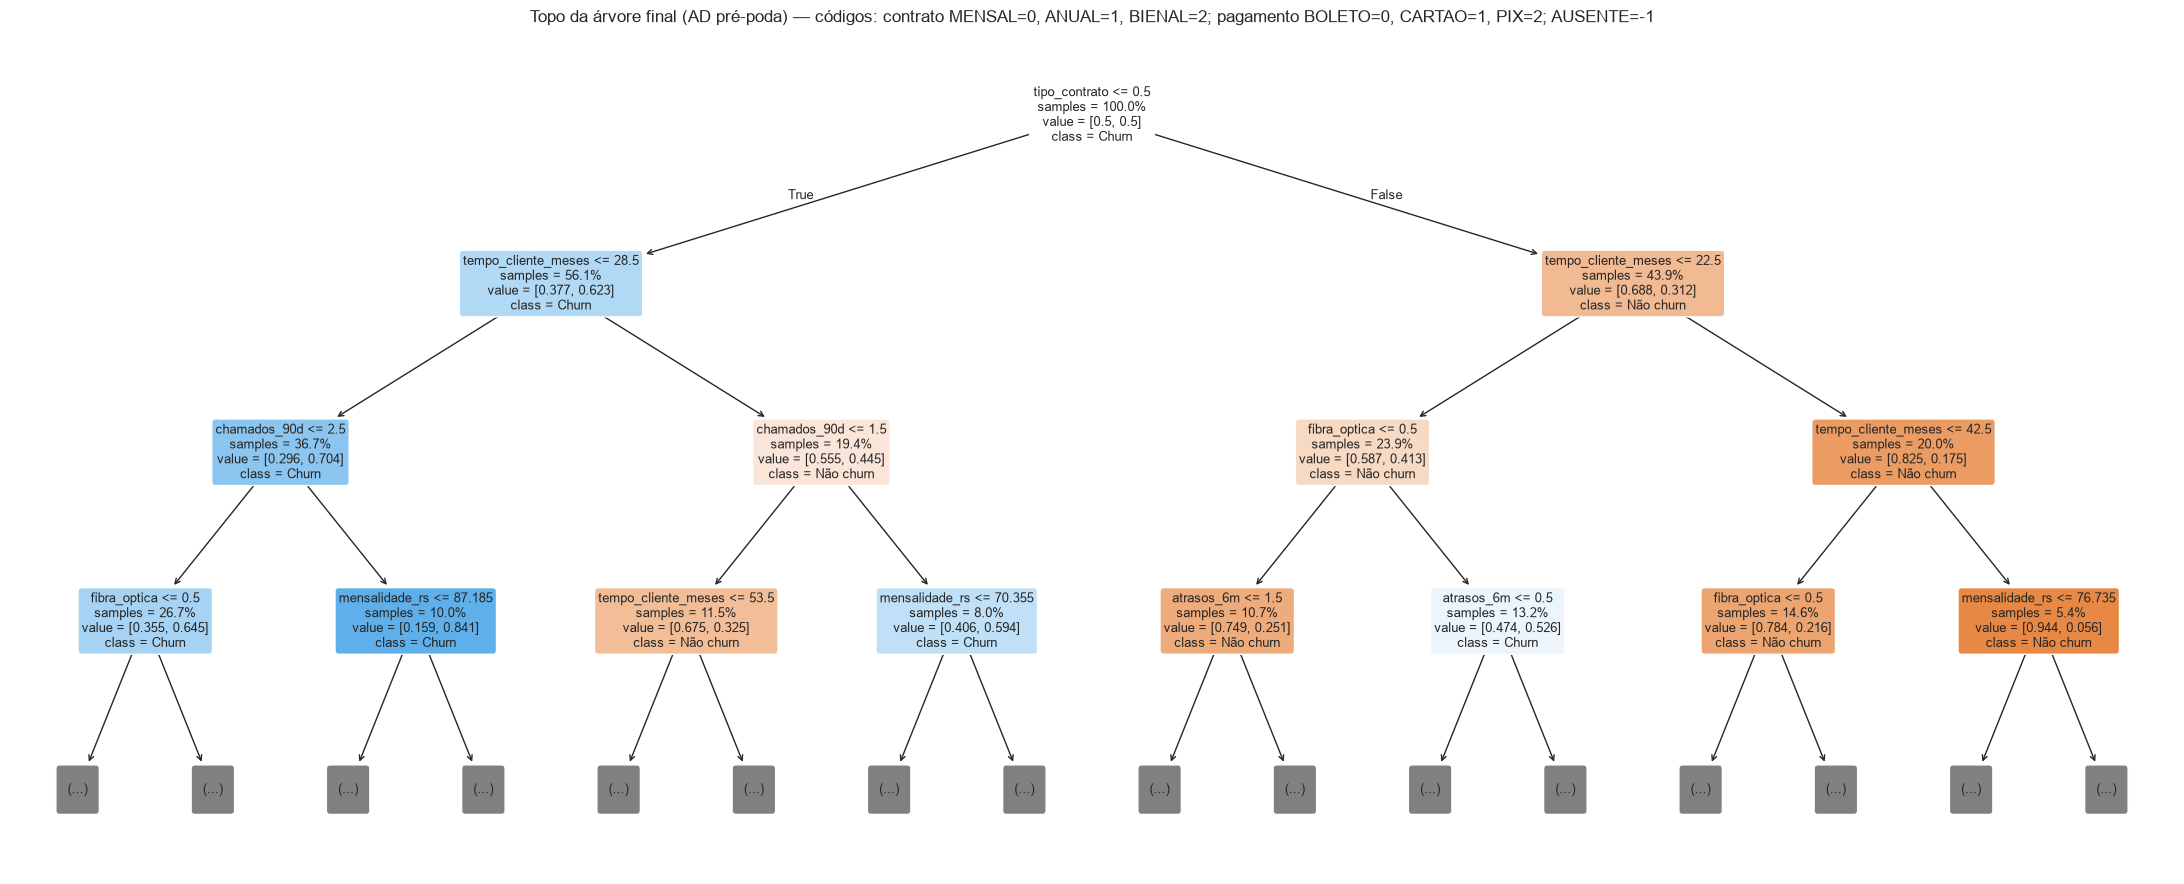

In [19]:
fig, eixo = plt.subplots(figsize=(22, 9))
plot_tree(
    AD_FINAL.named_steps["modelo"], max_depth=PROFUNDIDADE_REGRAS, feature_names=ATRIBUTOS,
    class_names=["Não churn", "Churn"], filled=True, rounded=True, impurity=False,
    proportion=True, fontsize=9, ax=eixo
)
eixo.set_title(f"Topo da árvore final ({NOME_AD_FINAL}) — códigos: contrato MENSAL=0, ANUAL=1, BIENAL=2; "
               f"pagamento BOLETO=0, CARTAO=1, PIX=2; AUSENTE=-1")
plt.tight_layout()
plt.show()

#### 5.5.1 Folhas de maior e menor risco

Além do topo, listamos as folhas completas da árvore com maior taxa de churn (perfis prioritários para retenção) e as de menor risco, considerando apenas folhas com pelo menos 1% dos clientes do treino, para evitar regras baseadas em poucos casos.

In [20]:
regras_folhas = extrair_regras(AD_FINAL, X_treino, y_treino)
relevantes = regras_folhas[regras_folhas["suporte (%)"] >= 1.0]
print(f"Folhas: {len(regras_folhas)} no total, {len(relevantes)} com suporte ≥ 1%\n")

print("--- 5 PERFIS DE MAIOR RISCO ---\n")
imprimir_regras(relevantes.head(5))
print("--- 5 PERFIS DE MENOR RISCO ---\n")
imprimir_regras(relevantes.tail(5).iloc[::-1])

Folhas: 52 no total, 52 com suporte ≥ 1%

--- 5 PERFIS DE MAIOR RISCO ---

SE tipo_contrato ∈ {AUSENTE, MENSAL} E tempo_cliente_meses <= 28 E chamados_90d >= 3 E mensalidade_rs > R$ 101.24 E atrasos_6m >= 1
    ENTÃO CHURN  [69 clientes, 2.0% do treino, churn real 89.9%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E tempo_cliente_meses <= 28 E chamados_90d >= 3 E mensalidade_rs <= R$ 87.18 E atrasos_6m >= 2
    ENTÃO CHURN  [54 clientes, 1.5% do treino, churn real 79.6%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E tempo_cliente_meses <= 28 E chamados_90d >= 3 E mensalidade_rs > R$ 87.18 e <= R$ 101.24 E atrasos_6m >= 1
    ENTÃO CHURN  [82 clientes, 2.3% do treino, churn real 79.3%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E tempo_cliente_meses <= 13 E chamados_90d <= 2 E fibra_optica = 1 E mensalidade_rs <= R$ 104.72 E atrasos_6m >= 2
    ENTÃO CHURN  [52 clientes, 1.5% do treino, churn real 78.8%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E tempo_cliente_meses <= 28 E chamados_90d <= 2 E fibra_optica

### 5.6 Importância dos atributos

Comparamos duas medidas:

- **Importância por impureza** (`feature_importances_`): quanto cada atributo reduziu a impureza nas divisões da árvore final. É rápida, mas medida no próprio treino e enviesada a favor de atributos com muitos valores distintos.
- **Importância por permutação**: queda do **recall** na validação quando os valores de um atributo são embaralhados. Calculamos em cada uma das 5 partes da validação cruzada, com o modelo treinado nas outras 4, e tiramos a média. Isso mede o efeito real na métrica principal **sem usar o teste**.

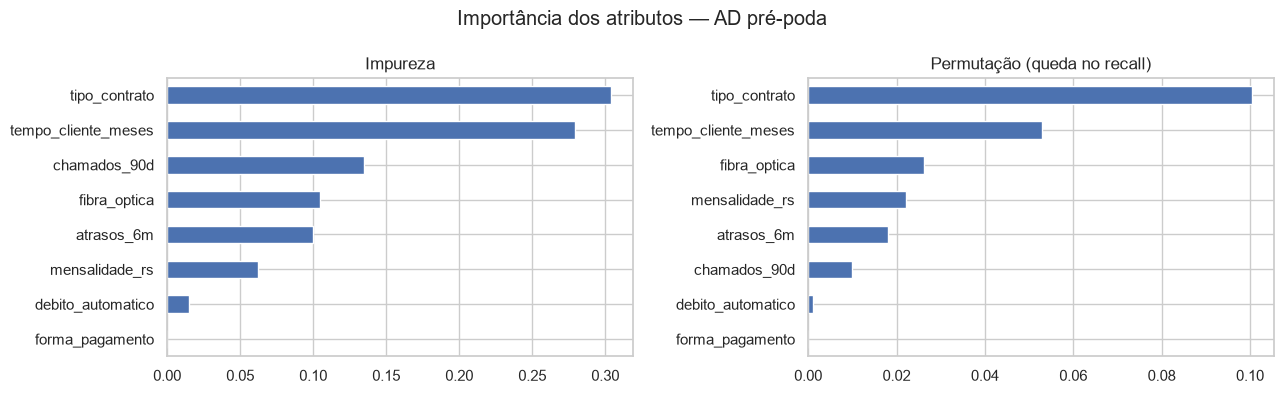

,Impureza,Permutação (queda no recall)
tipo_contrato,0.3038,0.1004
tempo_cliente_meses,0.2789,0.0529
chamados_90d,0.1350,0.0099
fibra_optica,0.1049,0.0261
atrasos_6m,0.1000,0.0181
mensalidade_rs,0.0625,0.0222
debito_automatico,0.0150,0.0011
forma_pagamento,0.0000,0.0000


In [21]:
from sklearn.inspection import permutation_importance


def importancia_permutacao_cv(pipeline, scoring="recall", n_repeats=10):
    importancias = []
    for idx_treino, idx_val in CV.split(X_treino, y_treino):
        modelo = clone(pipeline).fit(X_treino.iloc[idx_treino], y_treino.iloc[idx_treino])
        r = permutation_importance(
            modelo, X_treino.iloc[idx_val], y_treino.iloc[idx_val],
            scoring=scoring, n_repeats=n_repeats, random_state=SEED, n_jobs=-1
        )
        importancias.append(r.importances_mean)
    return pd.Series(np.mean(importancias, axis=0), index=X_treino.columns)


importancia_ad = pd.DataFrame({
    "Impureza": pd.Series(AD_FINAL.named_steps["modelo"].feature_importances_, index=ATRIBUTOS),
    "Permutação (queda no recall)": importancia_permutacao_cv(AD_FINAL),
}).sort_values("Impureza", ascending=False)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for eixo, coluna in zip(eixos, importancia_ad.columns):
    importancia_ad[coluna].sort_values().plot.barh(ax=eixo)
    eixo.set_title(coluna)
fig.suptitle(f"Importância dos atributos — {NOME_AD_FINAL}")
plt.tight_layout()
plt.show()
display(importancia_ad.round(4))

### 5.7 Conclusões parciais da Árvore de Decisão

**Referências.** Os modelos triviais confirmam o problema das métricas isoladas: "sempre não churn" tem 64,5% de acurácia e recall zero; "sempre churn" tem recall 1,0 e até F2 = 0,733, mas PR-AUC igual à prevalência (0,355). A regressão logística atinge PR-AUC = 0,670 e ROC-AUC = 0,798, sem overfitting (gap ≈ 0,01).

**Overfitting da árvore livre.** Sem restrições, a árvore chega a 25 níveis e 932 folhas: recall de ~1,0 no treino contra 0,49 na validação (gap de 0,51) e PR-AUC de apenas 0,43.

**Pré-poda × pós-poda** (critério: PR-AUC na validação cruzada):

| | PR-AUC (val) | ROC-AUC (val) | Precisão com recall 80% | Gap recall | Profundidade | Folhas |
|---|---|---|---|---|---|---|
| Sem restrições | 0,427 | 0,611 | — | 0,507 | 25 | 932 |
| **Pré-poda** (`max_depth=8`, `min_samples_leaf=50`, `entropy`, `balanced`) | **0,618** | **0,765** | **0,518** | 0,033 | 8 | 52 |
| Pós-poda (`ccp_alpha≈0,0023`) | 0,578 | 0,749 | 0,508 | 0,043 | 7 | 23 |

- A **pré-poda venceu**. O hiperparâmetro decisivo foi `min_samples_leaf=50`: com folhas de pelo menos 50 clientes (~1,4% do treino), `max_depth` 8, 10 ou ilimitado empatam, porque as folhas mínimas é que freiam o crescimento. Na etapa B, nenhum dos hiperparâmetros extras melhorou o resultado.
- A curva de validação mostra a PR-AUC de validação no máximo em `max_depth = 5` (0,590) e caindo depois, enquanto a de treino sobe até ~1,0: a assinatura clássica de overfitting.
- A pós-poda gera uma árvore menor (23 folhas), mais simples de explicar, com perda de 0,04 de PR-AUC. É uma alternativa razoável quando a interpretabilidade for prioridade.

**Comparação com a regressão logística.** Mesmo podada, a árvore fica abaixo da logística em PR-AUC (0,618 × 0,670) e em precisão com recall de 80% (0,518 × 0,550). A árvore ganha em interpretabilidade; a relação entre os atributos e o churn parece ser em boa parte aditiva, o que favorece o modelo linear.

**Regras e atributos de risco.** O tipo de contrato é a primeira divisão e o atributo mais importante, seguido de tempo de cliente e chamados em 90 dias.
- Maior risco no topo da árvore: **contrato mensal, até 28 meses de casa e 3 ou mais chamados** (74,5% de churn, contra 35,5% na base).
- Nos níveis mais profundos, mensalidade alta e atrasos aumentam ainda mais o risco: contrato mensal, até 28 meses, 3+ chamados, mensalidade acima de R$ 101 e ao menos 1 atraso → **90% de churn** (69 clientes).
- Menor risco: **contrato anual/bienal com 43 meses ou mais de casa** (3,2%).
- A forma de pagamento não foi usada pela árvore (importância zero nas duas medidas).

## 6. Módulo 2 — XGBoost

O XGBoost combina centenas de árvores rasas (*weak learners*). Cada nova árvore corrige os erros das anteriores, e a contribuição de cada uma é reduzida pela taxa de aprendizado (`learning_rate`). Seguimos o mesmo protocolo da Árvore de Decisão: pipeline com o template de pré-processamento, validação cruzada com as mesmas 5 partes, busca pela PR-AUC e ajuste de limiar out-of-fold.

Esta seção integra a versão exploratória do XGBoost desenvolvida pela integrante Juliana Silva, com três ajustes para manter o protocolo comum:

1. A busca do Optuna otimiza a **PR-AUC**, não o recall puro (a seção 6.3.1 compara recall, F2 e PR-AUC como objetivo).
2. As curvas de erro por iteração usam uma **parte de validação separada do treino**, nunca o teste.
3. A avaliação no teste fica para a seção final, junto com a Árvore de Decisão.

### 6.1 XGBoost com hiperparâmetros padrão

Referência inicial: o XGBoost sem ajuste nenhum (100 árvores, profundidade 6, `learning_rate` 0,3), sem compensar o desbalanceamento das classes.

In [22]:
from xgboost import XGBClassifier

XGB_FIXOS = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "random_state": SEED,
    "n_jobs": 1,  # o paralelismo fica na validação cruzada
}

avaliar_cv("XGB padrão", montar_pipeline(XGBClassifier(**XGB_FIXOS)))
display(tabela_cv(["Regressão logística", NOME_AD_FINAL, "XGB padrão"]))

,pr_auc (val),roc_auc (val),recall (val),precision (val),f1 (val),f2 (val),gap recall (treino-val),gap acurácia (treino-val),tempo (s)
Regressão logística,0.670,0.798,0.729,0.583,0.648,0.694,0.006,0.004,6.944
AD pré-poda,0.618,0.765,0.722,0.553,0.626,0.680,0.033,0.024,126.625
XGB padrão,0.606,0.750,0.535,0.579,0.556,0.543,0.385,0.257,2.096


### 6.2 Busca em grade (`GridSearchCV`)

A grade cobre os oito hiperparâmetros do enunciado com valores contrastantes, para medir o efeito de cada um sem explodir o número de combinações (2⁷ × 3 = 384 combinações × 5 partes = 1.920 ajustes).

| Hiperparâmetro | Valores | Justificativa |
|---|---|---|
| `n_estimators` | 100, 300 | Poucas × muitas árvores; o trade-off com `learning_rate` é estudado em detalhe na seção 6.5. |
| `learning_rate` | 0,03, 0,1 | Faixa usual em boosting; 0,3 (padrão) tende a overfitting em base pequena. |
| `max_depth` | 2, 3, 5 | No boosting, árvores rasas são o padrão; a AD mostrou que profundidade 3 já captura as interações principais. |
| `subsample` | 0,8, 1,0 | Amostrar 80% dos clientes por árvore adiciona aleatoriedade e reduz variância. |
| `colsample_bytree` | 0,7, 1,0 | Idem para atributos; com apenas 8 colunas, valores muito baixos removeriam o contrato de muitas árvores. |
| `gamma` | 0, 1 | Ganho mínimo para dividir um nó (pré-poda interna do XGBoost). |
| `reg_alpha` | 0, 1 | Regularização L1 dos pesos das folhas. |
| `reg_lambda` | 1, 5 | Regularização L2 (1 é o padrão). |
| `scale_pos_weight` | fixo em 1,82 | Razão negativos/positivos do treino: equivalente ao `class_weight="balanced"` que foi decisivo na AD. O Optuna explora esse valor livremente. |

In [23]:
grade_xgb = {
    "modelo__n_estimators": [100, 300],
    "modelo__learning_rate": [0.03, 0.1],
    "modelo__max_depth": [2, 3, 5],
    "modelo__subsample": [0.8, 1.0],
    "modelo__colsample_bytree": [0.7, 1.0],
    "modelo__gamma": [0, 1],
    "modelo__reg_alpha": [0, 1],
    "modelo__reg_lambda": [1, 5],
}

busca_xgb_grid = GridSearchCV(
    montar_pipeline(XGBClassifier(**XGB_FIXOS, scale_pos_weight=PROPORCAO_NEG_POS)),
    grade_xgb, scoring=METRICAS, refit=METRICA_BUSCA, cv=CV,
    n_jobs=-1, return_train_score=True
)
inicio = time.perf_counter()
busca_xgb_grid.fit(X_treino, y_treino)
tempo_xgb_grid = time.perf_counter() - inicio

registrar_busca("XGB GridSearch", busca_xgb_grid, tempo_xgb_grid)
n_comb_xgb = len(busca_xgb_grid.cv_results_["params"])
print(f"GridSearch: {n_comb_xgb} combinações × 5 partes = {n_comb_xgb * 5} ajustes em {tempo_xgb_grid:.1f} s")
print(f"Melhor PR-AUC (val): {busca_xgb_grid.best_score_:.4f}")
print("Melhores hiperparâmetros:", {k.replace("modelo__", ""): v for k, v in busca_xgb_grid.best_params_.items()})
display(top_combinacoes(busca_xgb_grid))

GridSearch: 384 combinações × 5 partes = 1920 ajustes em 91.6 s
Melhor PR-AUC (val): 0.6659
Melhores hiperparâmetros: {'colsample_bytree': 1.0, 'gamma': 1, 'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100, 'reg_alpha': 1, 'reg_lambda': 1, 'subsample': 0.8}


,colsample_bytree,gamma,learning_rate,max_depth,n_estimators,reg_alpha,reg_lambda,subsample,mean_test_pr_auc,mean_test_f2,mean_test_recall,mean_test_precision,mean_train_pr_auc,rank_test_pr_auc
340,1.0,1,0.10,2,100,1,1,0.8,0.6659,0.7014,0.7419,0.5759,0.6984,1
12,0.7,0,0.03,2,300,1,1,0.8,0.6656,0.7027,0.7427,0.5785,0.6939,2
244,1.0,0,0.10,2,100,1,1,0.8,0.6654,0.7021,0.7427,0.5765,0.6989,3
144,0.7,1,0.10,2,100,0,1,0.8,0.6653,0.7002,0.7395,0.5779,0.6981,4
241,1.0,0,0.10,2,100,0,1,1.0,0.6652,0.6998,0.7411,0.5727,0.7020,5
8,0.7,0,0.03,2,300,0,1,0.8,0.6652,0.6993,0.7387,0.5770,0.6964,6
246,1.0,0,0.10,2,100,1,5,0.8,0.6651,0.6962,0.7339,0.5778,0.6954,7
108,0.7,1,0.03,2,300,1,1,0.8,0.6650,0.7007,0.7403,0.5774,0.6940,8
337,1.0,1,0.10,2,100,0,1,1.0,0.6650,0.7018,0.7427,0.5753,0.7015,9
134,0.7,1,0.03,5,100,1,5,0.8,0.6649,0.6900,0.7282,0.5704,0.7340,10


#### 6.2.1 Efeito de cada hiperparâmetro na grade

Para cada hiperparâmetro, mostramos a PR-AUC média de validação de todas as combinações que usam cada valor. É uma leitura marginal: indica quais escolhas pesam mais, mesmo sem isolar interações.

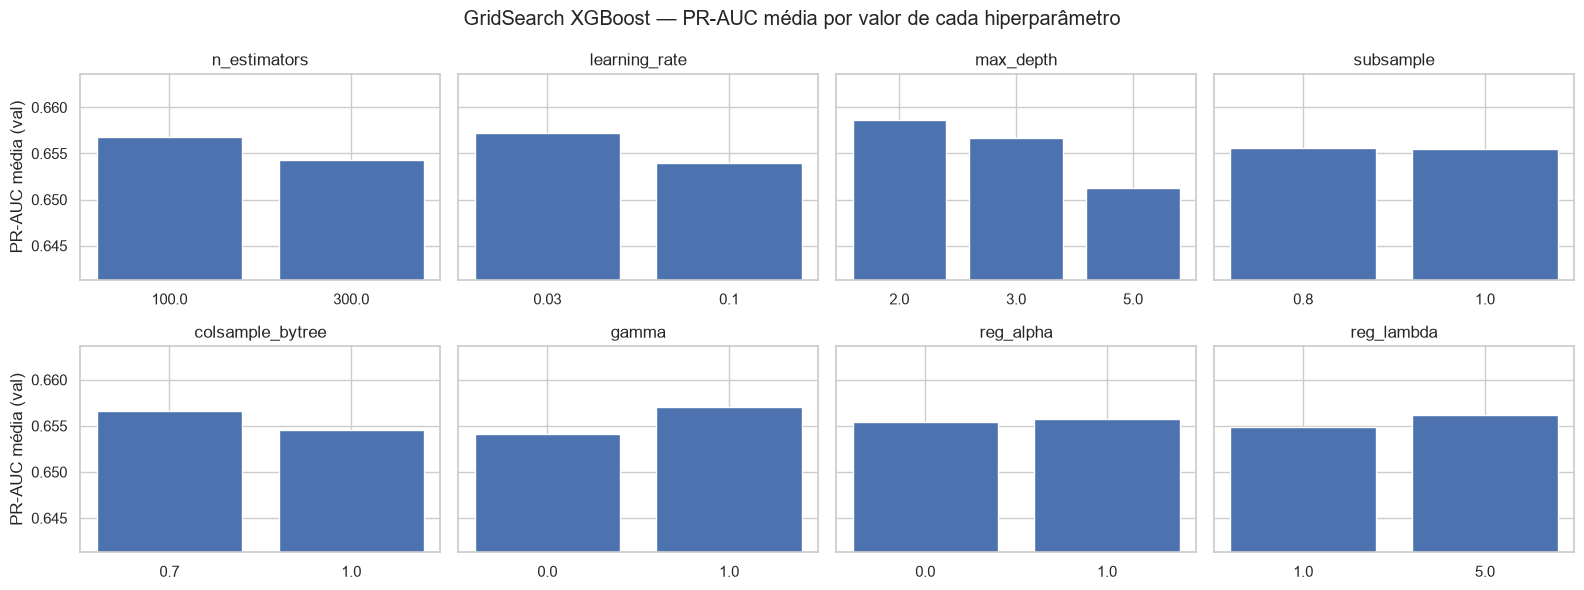

,hiperparâmetro,valor,PR-AUC val (média),gap PR-AUC treino-val
0,n_estimators,100.00,0.6568,0.0680
1,n_estimators,300.00,0.6543,0.1091
2,learning_rate,0.03,0.6572,0.0662
3,learning_rate,0.10,0.6539,0.1110
4,max_depth,2.00,0.6587,0.0367
5,max_depth,3.00,0.6567,0.0713
6,max_depth,5.00,0.6513,0.1577
7,subsample,0.80,0.6556,0.0946
8,subsample,1.00,0.6555,0.0825
9,colsample_bytree,0.70,0.6566,0.0829


In [24]:
res_grid = pd.DataFrame(busca_xgb_grid.cv_results_)
efeitos = []
for parametro in grade_xgb:
    nome = parametro.replace("modelo__", "")
    for valor, grupo in res_grid.groupby(f"param_{parametro}"):
        efeitos.append({"hiperparâmetro": nome, "valor": valor,
                        "PR-AUC val (média)": grupo["mean_test_pr_auc"].mean(),
                        "gap PR-AUC treino-val": (grupo["mean_train_pr_auc"] - grupo["mean_test_pr_auc"]).mean()})
efeitos = pd.DataFrame(efeitos)

fig, eixos = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
for eixo, (nome, grupo) in zip(eixos.ravel(), efeitos.groupby("hiperparâmetro", sort=False)):
    eixo.bar(grupo["valor"].astype(str), grupo["PR-AUC val (média)"])
    eixo.set_title(nome)
    eixo.set_ylim(efeitos["PR-AUC val (média)"].min() - 0.01, efeitos["PR-AUC val (média)"].max() + 0.005)
eixos[0, 0].set_ylabel("PR-AUC média (val)")
eixos[1, 0].set_ylabel("PR-AUC média (val)")
fig.suptitle("GridSearch XGBoost — PR-AUC média por valor de cada hiperparâmetro")
plt.tight_layout()
plt.show()
display(efeitos.round(4))

### 6.3 Otimização bayesiana com Optuna

O Optuna usa o amostrador TPE (*Tree-structured Parzen Estimator*): a cada tentativa, ele concentra a busca nas regiões do espaço que produziram bons resultados, explorando **valores contínuos** em vez de pontos fixos. Usamos também o **`MedianPruner`**: a PR-AUC é reportada após cada parte da validação cruzada, e uma tentativa é interrompida se estiver abaixo da mediana das anteriores no mesmo ponto. Isso economiza tempo em configurações ruins.

O espaço de busca parte da versão exploratória da Juliana e acrescenta `min_child_weight` (peso mínimo de amostras por folha, que controla folhas pequenas). `scale_pos_weight` varia livremente entre 1 (sem compensação) e 3.

In [25]:
import optuna
from optuna.exceptions import ExperimentalWarning
from sklearn.metrics import average_precision_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=ExperimentalWarning)

N_TENTATIVAS = 100
DIVISOES_CV = list(CV.split(X_treino, y_treino))


def espaco_xgb(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 50, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 30, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 3.0),
    }


def objetivo_pr_auc(trial):
    pipeline = montar_pipeline(XGBClassifier(**XGB_FIXOS | {"n_jobs": -1}, **espaco_xgb(trial)))
    notas = []
    for k, (idx_tr, idx_val) in enumerate(DIVISOES_CV):
        modelo = clone(pipeline).fit(X_treino.iloc[idx_tr], y_treino.iloc[idx_tr])
        proba = modelo.predict_proba(X_treino.iloc[idx_val])[:, 1]
        notas.append(average_precision_score(y_treino.iloc[idx_val], proba))
        trial.report(np.mean(notas), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(notas)


estudo_xgb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1),
    study_name="xgb_pr_auc",
)
inicio = time.perf_counter()
estudo_xgb.optimize(objetivo_pr_auc, n_trials=N_TENTATIVAS)
tempo_xgb_optuna = time.perf_counter() - inicio

estados = pd.Series([t.state.name for t in estudo_xgb.trials]).value_counts()
print(f"Optuna: {N_TENTATIVAS} tentativas em {tempo_xgb_optuna:.1f} s "
      f"({estados.get('COMPLETE', 0)} completas, {estados.get('PRUNED', 0)} interrompidas pelo pruner)")
print(f"Melhor PR-AUC (val): {estudo_xgb.best_value:.4f}")
print("Melhores hiperparâmetros:")
for k, v in estudo_xgb.best_params.items():
    print(f"  {k}: {v:.4g}" if isinstance(v, float) else f"  {k}: {v}")

Optuna: 100 tentativas em 116.2 s (35 completas, 65 interrompidas pelo pruner)
Melhor PR-AUC (val): 0.6651
Melhores hiperparâmetros:
  n_estimators: 599
  learning_rate: 0.01906
  max_depth: 5
  min_child_weight: 16.94
  subsample: 0.7147
  colsample_bytree: 0.9465
  gamma: 3.103
  reg_alpha: 0.1761
  reg_lambda: 0.4697
  scale_pos_weight: 1.372


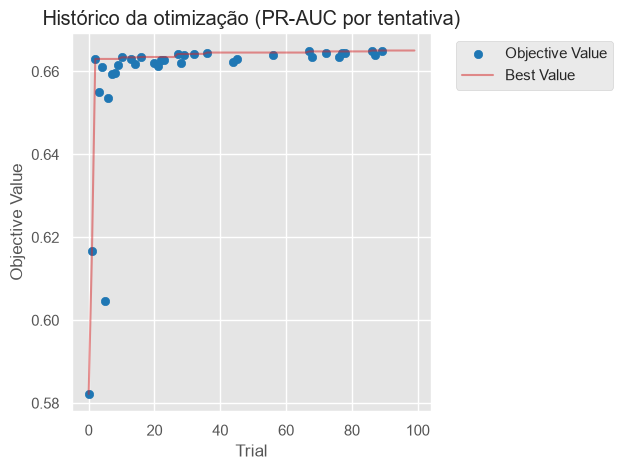

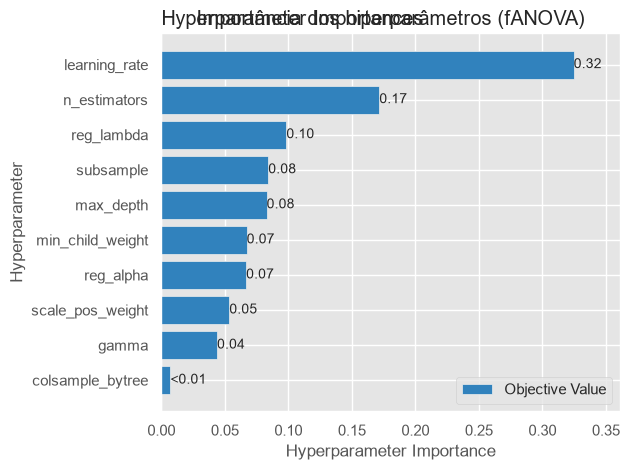

C:\Users\clebe\AppData\Local\Temp\ipykernel_13940\578897707.py:16: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


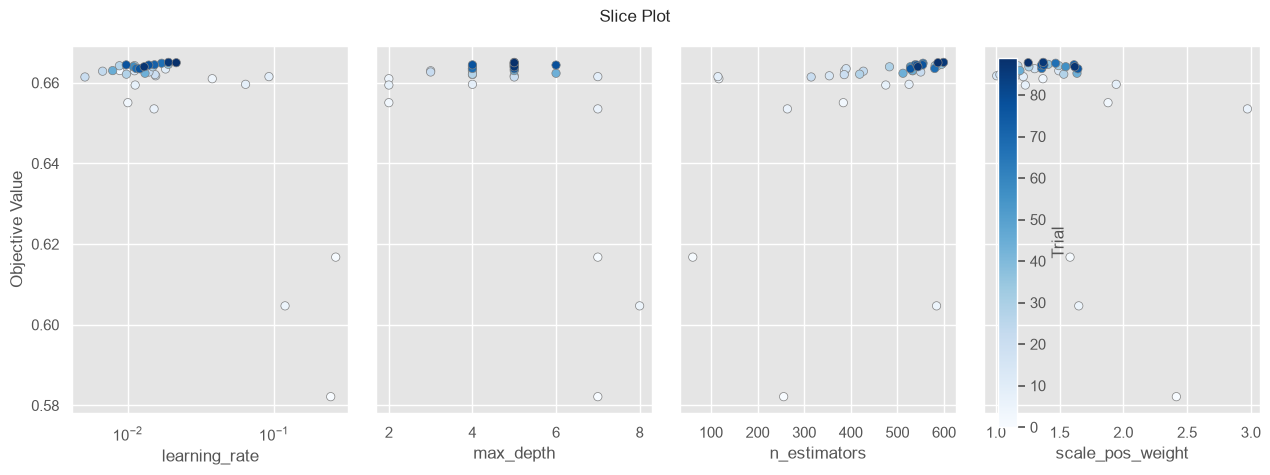

In [26]:
from optuna.visualization.matplotlib import (
    plot_optimization_history, plot_param_importances, plot_slice
)

plot_optimization_history(estudo_xgb)
plt.title("Histórico da otimização (PR-AUC por tentativa)")
plt.tight_layout()
plt.show()

plot_param_importances(estudo_xgb)
plt.title("Importância dos hiperparâmetros (fANOVA)")
plt.tight_layout()
plt.show()

plot_slice(estudo_xgb, params=["learning_rate", "n_estimators", "max_depth", "scale_pos_weight"])
plt.tight_layout()
plt.show()

#### 6.3.1 Reavaliação com o protocolo comum

O Optuna registrou apenas a PR-AUC. Reavaliamos a melhor configuração com `avaliar_cv`, nas mesmas 5 partes, para obter todas as métricas e o gap treino-validação, comparáveis às dos demais modelos.

**Comparação do objetivo da busca.** Reavaliamos também as melhores configurações de duas buscas anteriores com o mesmo espaço, guardadas aqui como valores fixos:

- **Optuna maximizando só o recall** (versão exploratória da Juliana, 60 tentativas);
- **Optuna maximizando o F2** (versão anterior deste notebook, 100 tentativas, valores arredondados a 4 algarismos).

A comparação justa entre as três é a **precisão com recall de 80%** (ajuste de limiar logo abaixo): com o ponto de operação igualado, sobra apenas a qualidade do modelo.

In [27]:
PARAMS_XGB_OPTUNA = estudo_xgb.best_params

avaliar_cv("XGB Optuna (PR-AUC)", montar_pipeline(XGBClassifier(**XGB_FIXOS, **PARAMS_XGB_OPTUNA)))
RESULTADOS_CV["XGB Optuna (PR-AUC)"]["tempo (s)"] = tempo_xgb_optuna

# Melhor configuração do Optuna focado em F2 (versão anterior deste notebook, 100 tentativas)
PARAMS_XGB_F2 = {
    "n_estimators": 144, "learning_rate": 0.005107, "max_depth": 7, "min_child_weight": 9.684,
    "subsample": 0.8729, "colsample_bytree": 0.5813, "gamma": 0.2139, "reg_alpha": 0.03725,
    "reg_lambda": 2.214e-07, "scale_pos_weight": 2.79,
}
avaliar_cv("XGB Optuna (F2)", montar_pipeline(XGBClassifier(**XGB_FIXOS, **PARAMS_XGB_F2)))

# Melhor configuração do Optuna focado em recall (versão exploratória da Juliana, 60 tentativas)
PARAMS_XGB_RECALL = {
    "n_estimators": 214, "learning_rate": 0.012916943381414525, "max_depth": 2,
    "subsample": 0.9400090714113671, "colsample_bytree": 0.5315400482995369,
    "gamma": 4.509725281469893, "reg_alpha": 7.754494341055396e-06,
    "reg_lambda": 1.8341863717650742e-07, "scale_pos_weight": 2.932200966656353,
}
avaliar_cv("XGB Optuna (só recall)", montar_pipeline(XGBClassifier(**XGB_FIXOS, **PARAMS_XGB_RECALL)))

display(tabela_cv(["Dummy: sempre churn", "XGB padrão", "XGB GridSearch",
                   "XGB Optuna (PR-AUC)", "XGB Optuna (F2)", "XGB Optuna (só recall)"]))

for nome, params in [("XGB Optuna (PR-AUC)", PARAMS_XGB_OPTUNA), ("XGB Optuna (F2)", PARAMS_XGB_F2),
                     ("XGB Optuna (só recall)", PARAMS_XGB_RECALL)]:
    escolher_limiar(nome, montar_pipeline(XGBClassifier(**XGB_FIXOS, **params)), plotar=False)
print("--- MESMO PONTO DE OPERAÇÃO (RECALL ≈ 80%): QUAL OBJETIVO GERA O MELHOR MODELO? ---")
display(tabela_limiares(["XGB Optuna (PR-AUC)", "XGB Optuna (F2)", "XGB Optuna (só recall)"]))

,pr_auc (val),roc_auc (val),recall (val),precision (val),f1 (val),f2 (val),gap recall (treino-val),gap acurácia (treino-val),tempo (s)
Dummy: sempre churn,0.355,0.500,1.000,0.355,0.524,0.733,0.000,-0.000,6.761
XGB padrão,0.606,0.750,0.535,0.579,0.556,0.543,0.385,0.257,2.096
XGB GridSearch,0.666,0.795,0.742,0.576,0.648,0.701,0.023,0.020,91.608
XGB Optuna (PR-AUC),0.662,0.792,0.651,0.604,0.627,0.641,0.042,0.029,116.168
XGB Optuna (F2),0.658,0.790,0.949,0.445,0.606,0.774,0.032,0.037,0.687
XGB Optuna (só recall),0.648,0.786,0.901,0.484,0.630,0.768,0.012,0.011,0.572


--- MESMO PONTO DE OPERAÇÃO (RECALL ≈ 80%): QUAL OBJETIVO GERA O MELHOR MODELO? ---


,limiar,recall (limiar),precisão (limiar),F1 (limiar),F2 (limiar),"recall (0,5)","precisão (0,5)"
XGB Optuna (PR-AUC),0.362,0.804,0.544,0.649,0.734,0.651,0.604
XGB Optuna (F2),0.572,0.802,0.532,0.639,0.728,0.949,0.445
XGB Optuna (só recall),0.580,0.800,0.548,0.650,0.733,0.901,0.484


### 6.4 GridSearch × Optuna

Comparamos as duas estratégias de busca pela melhor PR-AUC, pelo número de configurações avaliadas e pelo tempo total.

In [28]:
comparacao_busca = pd.DataFrame({
    "GridSearchCV": {
        "melhor PR-AUC (val)": busca_xgb_grid.best_score_,
        "configurações avaliadas": n_comb_xgb,
        "ajustes de modelo": n_comb_xgb * 5,
        "tempo (s)": tempo_xgb_grid,
        "espaço": "8 hiperparâmetros, valores discretos",
    },
    "Optuna (TPE + MedianPruner)": {
        "melhor PR-AUC (val)": estudo_xgb.best_value,
        "configurações avaliadas": N_TENTATIVAS,
        "ajustes de modelo": sum(len(t.intermediate_values) for t in estudo_xgb.trials),
        "tempo (s)": tempo_xgb_optuna,
        "espaço": "10 hiperparâmetros, contínuos",
    },
}).T
display(comparacao_busca)

,melhor PR-AUC (val),configurações avaliadas,ajustes de modelo,tempo (s),espaço
GridSearchCV,0.665944,384,1920,91.607901,"8 hiperparâmetros, valores discretos"
Optuna (TPE + MedianPruner),0.665061,100,318,116.167827,"10 hiperparâmetros, contínuos"


### 6.5 Trade-off entre `n_estimators` e `learning_rate`

Cada árvore contribui com uma fração `learning_rate` da correção. Com taxa menor, cada passo é menor e são necessárias mais árvores para chegar ao mesmo ajuste; com taxa maior, o modelo converge com poucas árvores, mas passa mais rápido do ponto ideal e começa a memorizar ruído.

**Grade (a partir da versão exploratória da Juliana).** Fixamos os demais hiperparâmetros no melhor resultado do Optuna e variamos apenas os dois, medindo PR-AUC de validação e gap treino-validação.

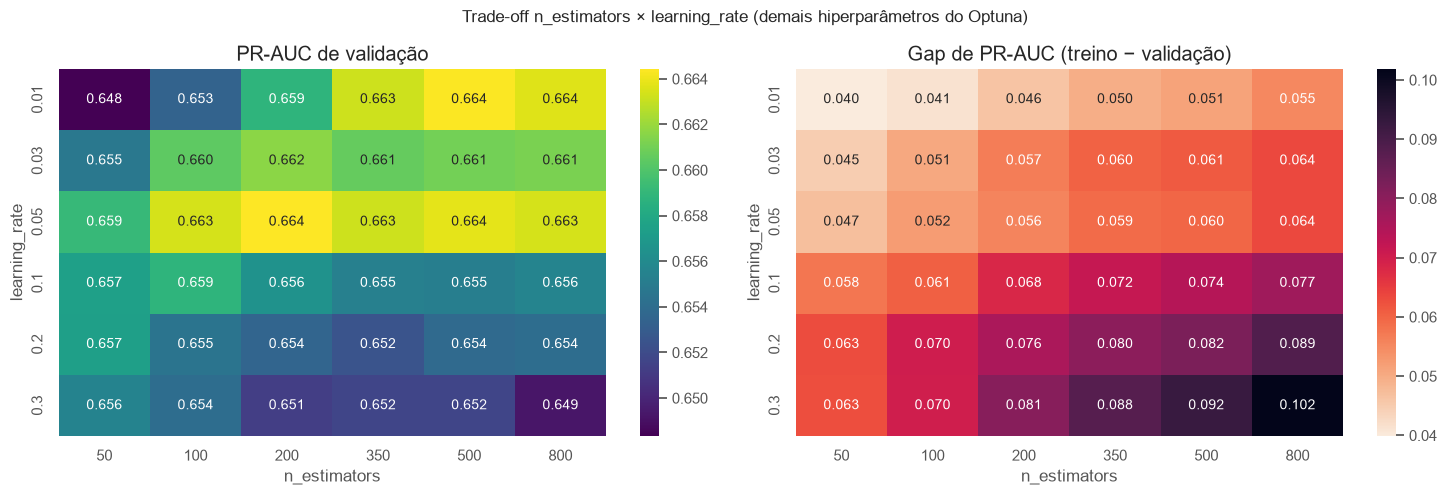

In [29]:
taxas = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3]
arvores = [50, 100, 200, 350, 500, 800]
base_tradeoff = {k: v for k, v in PARAMS_XGB_OPTUNA.items() if k not in ("learning_rate", "n_estimators")}

tradeoff = []
for lr in taxas:
    for n_est in arvores:
        r = cross_validate(
            montar_pipeline(XGBClassifier(**XGB_FIXOS, **base_tradeoff, learning_rate=lr, n_estimators=n_est)),
            X_treino, y_treino, cv=CV, scoring={"pr_auc": "average_precision", "recall": "recall"},
            return_train_score=True, n_jobs=-1
        )
        tradeoff.append({"learning_rate": lr, "n_estimators": n_est,
                         "PR-AUC val": r["test_pr_auc"].mean(), "recall val": r["test_recall"].mean(),
                         "gap PR-AUC": r["train_pr_auc"].mean() - r["test_pr_auc"].mean()})
tradeoff = pd.DataFrame(tradeoff)

fig, eixos = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(tradeoff.pivot(index="learning_rate", columns="n_estimators", values="PR-AUC val"),
            annot=True, fmt=".3f", cmap="viridis", ax=eixos[0])
eixos[0].set_title("PR-AUC de validação")
sns.heatmap(tradeoff.pivot(index="learning_rate", columns="n_estimators", values="gap PR-AUC"),
            annot=True, fmt=".3f", cmap="rocket_r", ax=eixos[1])
eixos[1].set_title("Gap de PR-AUC (treino − validação)")
fig.suptitle("Trade-off n_estimators × learning_rate (demais hiperparâmetros do Optuna)")
plt.tight_layout()
plt.show()

#### 6.5.1 Curvas de erro por iteração e *early stopping*

Para ver o trade-off árvore a árvore, separamos **20% do treino** (estratificado) como validação interna. O pré-processamento é ajustado só nos 80% restantes, e o XGBoost registra a logloss nos dois conjuntos a cada árvore. O **teste não é usado**.

Para cada taxa de aprendizado, marcamos a iteração de menor logloss na validação interna: é o número de árvores que um *early stopping* escolheria.

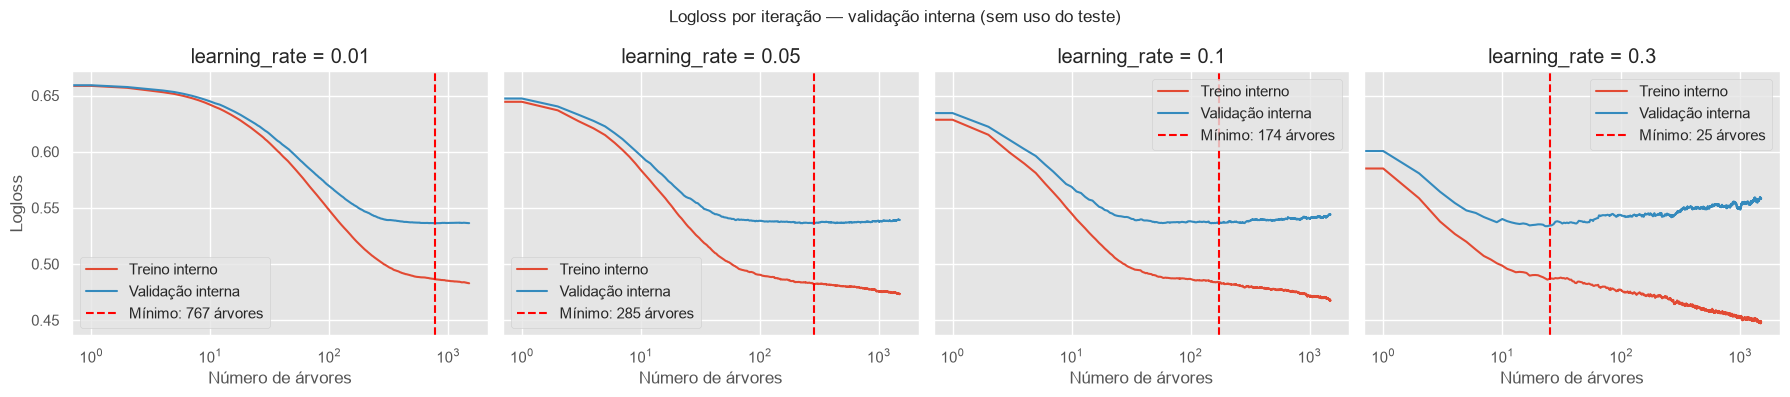

,learning_rate,árvores no mínimo,logloss val mínima,logloss val com 1500 árvores
0,0.01,767,0.5363,0.5364
1,0.05,285,0.5360,0.5392
2,0.10,174,0.5361,0.5441
3,0.30,25,0.5337,0.5586


In [30]:
from sklearn.model_selection import train_test_split

X_int_tr, X_int_val, y_int_tr, y_int_val = train_test_split(
    X_treino, y_treino, test_size=0.20, stratify=y_treino, random_state=SEED
)
prep_interno = clone(PREPROCESSADOR_TEMPLATE).fit(X_int_tr)
Xp_int_tr, Xp_int_val = prep_interno.transform(X_int_tr), prep_interno.transform(X_int_val)

N_MAX_ARVORES = 1500
curvas_lr = {}
for lr in [0.01, 0.05, 0.1, 0.3]:
    modelo = XGBClassifier(**XGB_FIXOS | {"n_jobs": -1}, **base_tradeoff,
                           learning_rate=lr, n_estimators=N_MAX_ARVORES)
    modelo.fit(Xp_int_tr, y_int_tr, eval_set=[(Xp_int_tr, y_int_tr), (Xp_int_val, y_int_val)], verbose=False)
    historico = modelo.evals_result()
    curvas_lr[lr] = (np.array(historico["validation_0"]["logloss"]), np.array(historico["validation_1"]["logloss"]))

fig, eixos = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
resumo_curvas = []
for eixo, (lr, (treino_ll, val_ll)) in zip(eixos, curvas_lr.items()):
    melhor = int(np.argmin(val_ll)) + 1
    eixo.plot(treino_ll, label="Treino interno")
    eixo.plot(val_ll, label="Validação interna")
    eixo.axvline(melhor, color="red", linestyle="--", label=f"Mínimo: {melhor} árvores")
    eixo.set_title(f"learning_rate = {lr}")
    eixo.set_xlabel("Número de árvores")
    eixo.set_xscale("log")
    eixo.legend()
    resumo_curvas.append({"learning_rate": lr, "árvores no mínimo": melhor,
                          "logloss val mínima": val_ll.min(),
                          f"logloss val com {N_MAX_ARVORES} árvores": val_ll[-1]})
eixos[0].set_ylabel("Logloss")
fig.suptitle("Logloss por iteração — validação interna (sem uso do teste)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(resumo_curvas).round(4))

### 6.6 Escolha do XGBoost final e ajuste de limiar

Escolhemos entre GridSearch e Optuna pela maior PR-AUC de validação e aplicamos o ajuste de limiar para o recall-alvo de 80%.

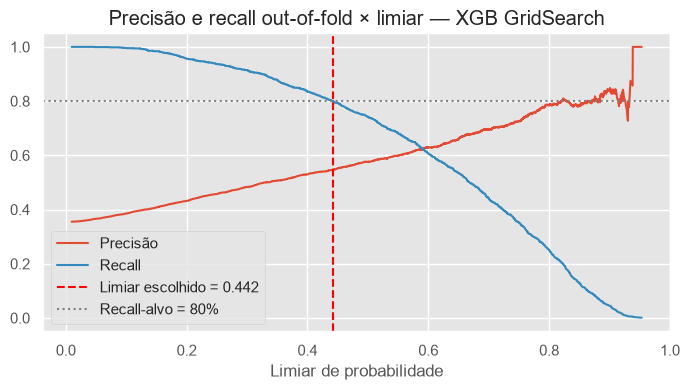

XGBoost final: XGB GridSearch | limiar = 0.442
--- COMPARAÇÃO NA VALIDAÇÃO CRUZADA ---


,pr_auc (val),roc_auc (val),recall (val),precision (val),f1 (val),f2 (val),gap recall (treino-val),gap acurácia (treino-val),tempo (s)
Regressão logística,0.670,0.798,0.729,0.583,0.648,0.694,0.006,0.004,6.944
AD pré-poda,0.618,0.765,0.722,0.553,0.626,0.680,0.033,0.024,126.625
XGB padrão,0.606,0.750,0.535,0.579,0.556,0.543,0.385,0.257,2.096
XGB GridSearch,0.666,0.795,0.742,0.576,0.648,0.701,0.023,0.020,91.608
XGB Optuna (PR-AUC),0.662,0.792,0.651,0.604,0.627,0.641,0.042,0.029,116.168
XGB Optuna (F2),0.658,0.790,0.949,0.445,0.606,0.774,0.032,0.037,0.687
XGB Optuna (só recall),0.648,0.786,0.901,0.484,0.630,0.768,0.012,0.011,0.572


--- AJUSTE DE LIMIAR (OUT-OF-FOLD NO TREINO, RECALL-ALVO 80%) ---


,limiar,recall (limiar),precisão (limiar),F1 (limiar),F2 (limiar),"recall (0,5)","precisão (0,5)"
Regressão logística,0.435,0.801,0.550,0.652,0.734,0.729,0.583
AD pré-poda,0.425,0.805,0.518,0.630,0.725,0.722,0.552
XGB GridSearch,0.442,0.800,0.547,0.650,0.732,0.742,0.576


In [31]:
candidatos_xgb = {
    "XGB GridSearch": busca_xgb_grid.best_estimator_,
    "XGB Optuna (PR-AUC)": montar_pipeline(XGBClassifier(**XGB_FIXOS, **PARAMS_XGB_OPTUNA)),
}
NOME_XGB_FINAL = max(candidatos_xgb, key=lambda n: RESULTADOS_CV[n][f"{METRICA_BUSCA} (val)"])
XGB_FINAL = clone(candidatos_xgb[NOME_XGB_FINAL]).fit(X_treino, y_treino)

LIMIAR_XGB, _ = escolher_limiar(NOME_XGB_FINAL, clone(XGB_FINAL))
print(f"XGBoost final: {NOME_XGB_FINAL} | limiar = {LIMIAR_XGB:.3f}")

print("--- COMPARAÇÃO NA VALIDAÇÃO CRUZADA ---")
display(tabela_cv(["Regressão logística", NOME_AD_FINAL, "XGB padrão", "XGB GridSearch",
                   "XGB Optuna (PR-AUC)", "XGB Optuna (F2)", "XGB Optuna (só recall)"]))
print("--- AJUSTE DE LIMIAR (OUT-OF-FOLD NO TREINO, RECALL-ALVO 80%) ---")
display(tabela_limiares(["Regressão logística", NOME_AD_FINAL, NOME_XGB_FINAL]))

### 6.7 Importância dos atributos no XGBoost

Comparamos quatro medidas:

- **Gain**: ganho médio de qualidade nas divisões que usam o atributo (a mais informativa das nativas).
- **Weight**: quantas vezes o atributo é usado em divisões. Favorece atributos contínuos, com muitos pontos de corte possíveis.
- **Permutação**: queda do recall na validação cruzada ao embaralhar o atributo (mesma função usada na AD).
- **SHAP**: contribuição de cada atributo para a previsão de cada cliente, com **direção** (aumenta ou reduz o risco). Calculado no treino.

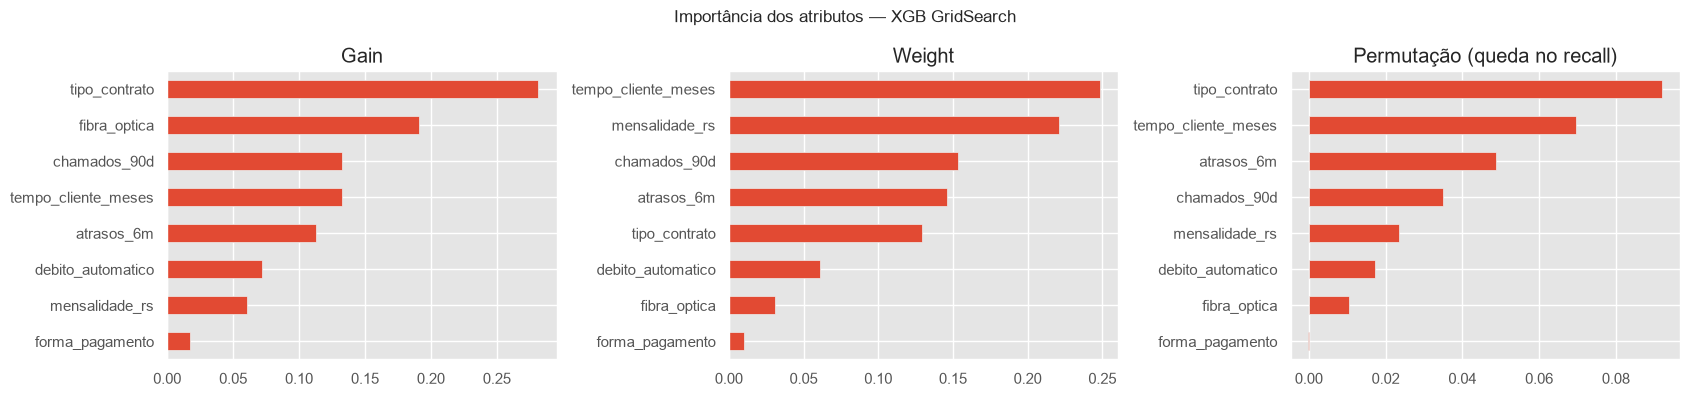

--- RANKING DE IMPORTÂNCIA: ÁRVORE DE DECISÃO × XGBOOST ---


,AD — impureza,AD — permutação,XGB — gain,XGB — permutação
tipo_contrato,0.3038,0.1004,0.2813,0.0921
fibra_optica,0.1049,0.0261,0.1910,0.0106
chamados_90d,0.1350,0.0099,0.1328,0.0349
tempo_cliente_meses,0.2789,0.0529,0.1328,0.0696
atrasos_6m,0.1000,0.0181,0.1126,0.0488
debito_automatico,0.0150,0.0011,0.0716,0.0173
mensalidade_rs,0.0625,0.0222,0.0606,0.0234
forma_pagamento,0.0000,0.0000,0.0173,-0.0002


In [32]:
booster = XGB_FINAL.named_steps["modelo"].get_booster()
importancia_xgb = pd.DataFrame({
    "Gain": pd.Series(booster.get_score(importance_type="gain")),
    "Weight": pd.Series(booster.get_score(importance_type="weight")),
}).reindex(ATRIBUTOS).fillna(0)
importancia_xgb = importancia_xgb / importancia_xgb.sum()
importancia_xgb["Permutação (queda no recall)"] = importancia_permutacao_cv(XGB_FINAL)
importancia_xgb = importancia_xgb.sort_values("Gain", ascending=False)

fig, eixos = plt.subplots(1, 3, figsize=(17, 4))
for eixo, coluna in zip(eixos, importancia_xgb.columns):
    importancia_xgb[coluna].sort_values().plot.barh(ax=eixo)
    eixo.set_title(coluna)
fig.suptitle(f"Importância dos atributos — {NOME_XGB_FINAL}")
plt.tight_layout()
plt.show()

print("--- RANKING DE IMPORTÂNCIA: ÁRVORE DE DECISÃO × XGBOOST ---")
ranking = pd.DataFrame({
    f"AD — impureza": importancia_ad["Impureza"],
    f"AD — permutação": importancia_ad["Permutação (queda no recall)"],
    f"XGB — gain": importancia_xgb["Gain"],
    f"XGB — permutação": importancia_xgb["Permutação (queda no recall)"],
}).sort_values("XGB — gain", ascending=False)
display(ranking.round(4))

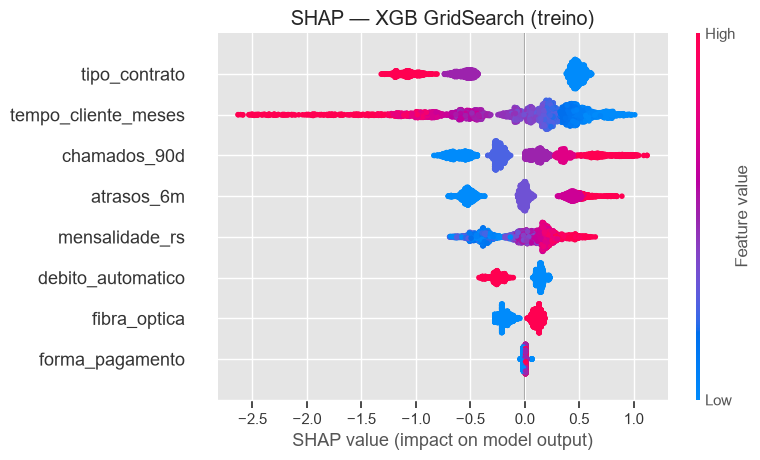

In [33]:
import shap

Xp_treino_final = XGB_FINAL.named_steps["prep"].transform(X_treino)
explicador = shap.TreeExplainer(XGB_FINAL.named_steps["modelo"])
valores_shap = explicador.shap_values(Xp_treino_final)

shap.summary_plot(valores_shap, Xp_treino_final, show=False)
plt.title(f"SHAP — {NOME_XGB_FINAL} (treino)")
plt.tight_layout()
plt.show()

### 6.8 Conclusões parciais do XGBoost

**Do padrão ao ajustado.** Sem ajuste, o XGBoost sofre overfitting forte (gap de recall de 0,39) e tem PR-AUC de 0,606, abaixo da árvore podada. Com a busca, a PR-AUC sobe para 0,666 e o gap cai para 0,02.

**GridSearch × Optuna.**

| | PR-AUC (val) | Configurações | Ajustes de modelo | Tempo |
|---|---|---|---|---|
| GridSearchCV | 0,666 | 384 | 1.920 | ~91 s |
| Optuna (TPE + MedianPruner) | 0,665 | 100 | 318 | ~112 s |

- As duas buscas chegam ao **mesmo patamar**. O Optuna usou **6× menos ajustes de modelo**, porque o pruner interrompeu 65 das 100 tentativas logo nas primeiras partes. O tempo foi parecido porque ele explorou modelos maiores (até 600 árvores).
- Hiperparâmetros com mais efeito na grade: `max_depth` (2 > 3 > 5; profundidade 5 quadruplica o gap de overfitting) e `learning_rate`/`n_estimators`. `subsample`, `reg_alpha` e `reg_lambda` quase não mudam o resultado.

**Trade-off `n_estimators` × `learning_rate`.** Nas curvas de logloss da validação interna, o número de árvores ideal cai à medida que a taxa sobe: **767 árvores com 0,01, 285 com 0,05, 174 com 0,1 e apenas 25 com 0,3**. A logloss mínima é praticamente a mesma (~0,536) em todos os casos. Taxas altas chegam lá rápido, mas pioram logo depois (logloss 0,559 com 1.500 árvores e taxa 0,3); taxas baixas são mais tolerantes a árvores em excesso.

**Objetivo da busca (6.3.1).** Recall puro, F2 e PR-AUC produzem modelos com **precisão entre 0,53 e 0,55 quando o recall é igualado em 80%**. A diferença entre eles está no ponto de corte escolhido implicitamente, não na capacidade de separar churners de não churners.

**Comparação geral (validação cruzada no treino).**

| Modelo | PR-AUC | ROC-AUC | Precisão com recall 80% |
|---|---|---|---|
| Regressão logística | **0,670** | **0,798** | **0,550** |
| XGBoost (GridSearch) | 0,666 | 0,795 | 0,547 |
| Árvore de Decisão (pré-poda) | 0,618 | 0,765 | 0,518 |

O XGBoost supera claramente a árvore única, mas **empata com a regressão logística**. Com 8 atributos e relações em boa parte monotônicas (contrato mais longo → menos churn; mais chamados → mais churn), há pouco espaço para as interações que o boosting captura. Esse "teto" dos dados é um resultado em si e será confirmado no teste.

**Importância dos atributos.** Os dois modelos concordam nos principais fatores: **tipo de contrato, tempo de cliente, chamados em 90 dias e atrasos**. O XGBoost distribui melhor a importância e passa a usar débito automático e mensalidade. A fibra óptica tem gain alto (0,19), mas pouca importância por permutação (0,01): sua informação se sobrepõe à de outros atributos. A forma de pagamento é irrelevante nos dois modelos.

## 7. Análise de overfitting

Até aqui, o gap foi medido entre treino e validação dentro da validação cruzada. Nesta seção:

1. Resumimos os gaps de todos os modelos testados.
2. Traçamos **curvas de aprendizado** (desempenho × tamanho do treino) para os três modelos finais: regressão logística, árvore e XGBoost. Elas mostram se o modelo memoriza (treino alto, validação baixa) e se mais dados ajudariam (validação ainda subindo no fim da curva).

O gap entre o treino completo (70%) e o teste (30%) é calculado na avaliação final (seção 9).

--- GAP TREINO × VALIDAÇÃO (MÉDIA DAS 5 PARTES) ---


,PR-AUC treino,PR-AUC val,gap PR-AUC,gap recall,gap acurácia
AD sem restrições,1.000,0.427,0.573,0.507,0.354
XGB padrão,0.984,0.606,0.379,0.385,0.257
AD pós-poda,0.652,0.578,0.074,0.043,0.033
AD pré-poda,0.669,0.618,0.051,0.033,0.024
XGB Optuna (PR-AUC),0.721,0.662,0.059,0.042,0.029
XGB GridSearch,0.698,0.666,0.032,0.023,0.020
Regressão logística,0.672,0.670,0.002,0.006,0.004


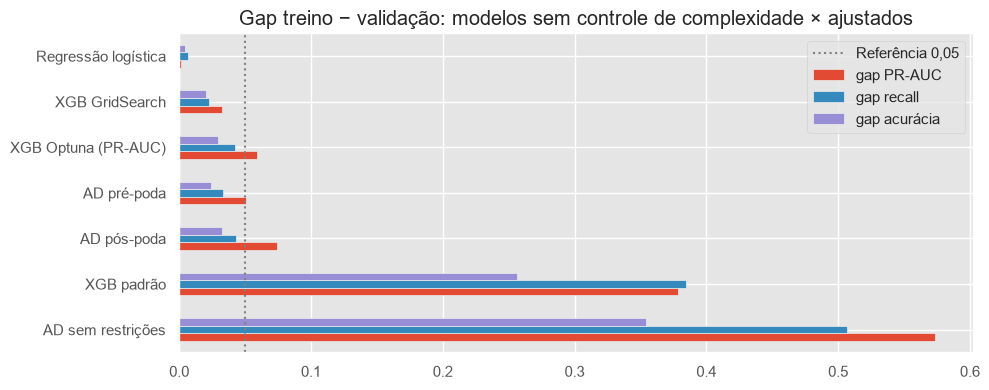

In [34]:
def montar_lr():
    return Pipeline([
        ("escala", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    ])


MODELOS_FINAIS = {
    "Regressão logística": montar_pipeline(montar_lr()),
    NOME_AD_FINAL: clone(AD_FINAL),
    NOME_XGB_FINAL: clone(XGB_FINAL),
}

nomes_gap = ["AD sem restrições", "XGB padrão", "AD pós-poda", "AD pré-poda", "XGB Optuna (PR-AUC)",
             "XGB GridSearch", "Regressão logística"]
gaps = pd.DataFrame(RESULTADOS_CV).T.astype(float).loc[nomes_gap]
gaps = pd.DataFrame({
    "PR-AUC treino": gaps["pr_auc (treino)"], "PR-AUC val": gaps["pr_auc (val)"],
    "gap PR-AUC": gaps["pr_auc (treino)"] - gaps["pr_auc (val)"],
    "gap recall": gaps["recall (treino)"] - gaps["recall (val)"],
    "gap acurácia": gaps["accuracy (treino)"] - gaps["accuracy (val)"],
})
print("--- GAP TREINO × VALIDAÇÃO (MÉDIA DAS 5 PARTES) ---")
display(gaps.round(3))

fig, eixo = plt.subplots(figsize=(10, 4))
gaps[["gap PR-AUC", "gap recall", "gap acurácia"]].plot.barh(ax=eixo)
eixo.axvline(0.05, color="gray", linestyle=":", label="Referência 0,05")
eixo.set_title("Gap treino − validação: modelos sem controle de complexidade × ajustados")
eixo.legend()
plt.tight_layout()
plt.show()

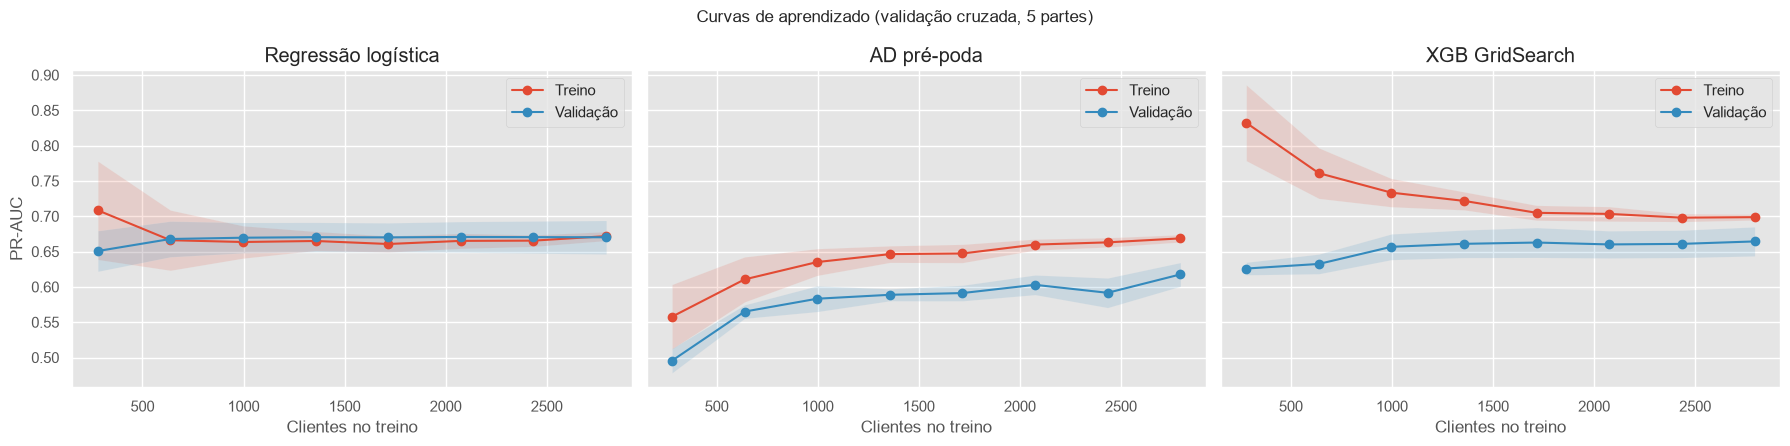

,PR-AUC treino (100%),PR-AUC val (100%),gap (100%),ganho na val de ~50% → 100% do treino
modelo,,,,
Regressão logística,0.672,0.670,0.002,-0.000
AD pré-poda,0.669,0.618,0.051,0.029
XGB GridSearch,0.699,0.664,0.034,0.003


In [35]:
from sklearn.model_selection import learning_curve

tamanhos = np.linspace(0.1, 1.0, 8)
idx_metade = int(np.argmin(np.abs(tamanhos - 0.5)))

fig, eixos = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
resumo_aprendizado = []
for eixo, (nome, pipeline) in zip(eixos, MODELOS_FINAIS.items()):
    n_treino, notas_tr, notas_val = learning_curve(
        pipeline, X_treino, y_treino, cv=CV, scoring="average_precision",
        train_sizes=tamanhos, shuffle=True, random_state=SEED, n_jobs=-1
    )
    for notas, rotulo in [(notas_tr, "Treino"), (notas_val, "Validação")]:
        eixo.plot(n_treino, notas.mean(axis=1), "o-", label=rotulo)
        eixo.fill_between(n_treino, notas.mean(axis=1) - notas.std(axis=1),
                          notas.mean(axis=1) + notas.std(axis=1), alpha=0.15)
    eixo.set_title(nome)
    eixo.set_xlabel("Clientes no treino")
    eixo.legend()
    resumo_aprendizado.append({
        "modelo": nome,
        "PR-AUC treino (100%)": notas_tr[-1].mean(),
        "PR-AUC val (100%)": notas_val[-1].mean(),
        "gap (100%)": notas_tr[-1].mean() - notas_val[-1].mean(),
        "ganho na val de ~50% → 100% do treino": notas_val[-1].mean() - notas_val[idx_metade].mean(),
    })
eixos[0].set_ylabel("PR-AUC")
fig.suptitle("Curvas de aprendizado (validação cruzada, 5 partes)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(resumo_aprendizado).set_index("modelo").round(3))

## 8. Hipóteses investigadas pela equipe

Testamos hipóteses além do roteiro, **todas por validação cruzada no treino**, antes de abrir o teste. Assim, o resultado de cada uma poderia mudar a escolha dos modelos finais sem contaminar a avaliação.

| # | Hipótese | Por que testar |
|---|---|---|
| H1 | A diferença entre XGBoost, regressão logística e árvore é real ou é ruído das partições? | Os modelos ficaram muito próximos na seção 6. |
| H2 | One-hot encoding funciona melhor que a codificação ordinal? | A issue #3 trocou one-hot por ordinal pensando em árvores; vale medir o efeito em cada modelo. |
| H3 | Deixar o XGBoost e a árvore tratarem os ausentes nativamente é melhor que imputar? | Os dois algoritmos aprendem uma direção padrão para valores ausentes, e a ausência pode carregar informação. |
| H4 | Atributos derivados das regras da árvore melhoram os modelos? | As regras indicaram interações (contrato mensal × cliente novo, chamados × atrasos). |
| H5 | Restrições monotônicas no XGBoost custam desempenho? | Impõem coerência de negócio (mais chamados nunca reduz o risco), útil para confiança no modelo. |

O critério já existente (precisão com recall de 80% e PR-AUC) também cobre a hipótese "recall × F2 × PR-AUC como objetivo da busca" (seção 6.3.1).

**Regra de adoção, definida antes de ver os resultados:** uma variante só substitui a configuração atual se aumentar a PR-AUC de validação em **pelo menos 0,01**. Abaixo disso, a diferença é da ordem do desvio entre partições.

In [36]:
from joblib import Parallel, delayed
from scipy import stats
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

GANHO_MINIMO = 0.01


def precisao_no_recall(y, proba, alvo=RECALL_ALVO):
    precisao, recall, _ = precision_recall_curve(y, proba)
    return precisao[:-1][recall[:-1] >= alvo].max()


def _avaliar_divisao(pipeline, idx_tr, idx_val):
    modelo = clone(pipeline).fit(X_treino.iloc[idx_tr], y_treino.iloc[idx_tr])
    return idx_val, modelo.predict_proba(X_treino.iloc[idx_val])[:, 1]


def avaliar_variante(pipeline):
    saidas = Parallel(n_jobs=-1)(delayed(_avaliar_divisao)(pipeline, a, b) for a, b in DIVISOES_CV)
    oof = np.empty(len(y_treino))
    pr_aucs, roc_aucs = [], []
    for idx_val, proba in saidas:
        oof[idx_val] = proba
        pr_aucs.append(average_precision_score(y_treino.iloc[idx_val], proba))
        roc_aucs.append(roc_auc_score(y_treino.iloc[idx_val], proba))
    return {
        "PR-AUC (val)": np.mean(pr_aucs), "PR-AUC dp": np.std(pr_aucs),
        "ROC-AUC (val)": np.mean(roc_aucs),
        "precisão c/ recall 80%": precisao_no_recall(y_treino, oof),
    }


def comparar_variantes(variantes, referencia):
    tabela = pd.DataFrame({nome: avaliar_variante(p) for nome, p in variantes.items()}).T
    tabela["Δ PR-AUC vs atual"] = tabela["PR-AUC (val)"] - tabela.loc[referencia, "PR-AUC (val)"]
    tabela["adotar?"] = np.where(tabela["Δ PR-AUC vs atual"] >= GANHO_MINIMO, "sim", "não")
    tabela.loc[referencia, "adotar?"] = "(atual)"
    return tabela.round(4)


MODELOS_BASE = {
    "Regressão logística": montar_lr,
    "AD": lambda: clone(AD_FINAL.named_steps["modelo"]),
    "XGBoost": lambda: clone(XGB_FINAL.named_steps["modelo"]),
}

### 8.1 H1: as diferenças entre os modelos são reais?

Com 5 partes, cada modelo tem só 5 medidas de PR-AUC. Repetimos a validação cruzada **5 vezes com embaralhamentos diferentes** (25 medidas por modelo, nas mesmas partições para todos) e aplicamos o **teste t corrigido de Nadeau & Bengio** para dados reamostrados. Ele infla a variância para compensar o fato de as partições de treino se sobreporem, evitando falsos positivos que um teste t comum produziria.

--- PR-AUC EM 5×5 PARTIÇÕES ---


,média,desvio
Regressão logística,0.6701,0.0232
AD pré-poda,0.6041,0.0236
XGB GridSearch,0.6633,0.0210


--- TESTE T CORRIGIDO (NADEAU & BENGIO) ---


,Δ PR-AUC médio,t corrigido,p-valor,significativo (5%)
comparação,,,,
Regressão logística − XGB GridSearch,0.0068,1.5004,0.1465,não
XGB GridSearch − AD pré-poda,0.0592,6.1944,0.0000,sim
Regressão logística − AD pré-poda,0.0660,6.1023,0.0000,sim


C:\Users\clebe\AppData\Local\Temp\ipykernel_13940\2124707115.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eixo.boxplot(list(notas_repetidas.values()), tick_labels=list(notas_repetidas.keys()), vert=False)


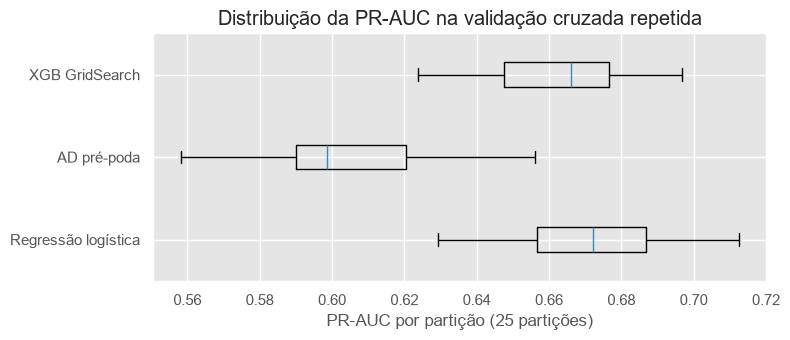

In [37]:
CV_REPETIDA = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
notas_repetidas = {
    nome: cross_validate(p, X_treino, y_treino, cv=CV_REPETIDA, scoring="average_precision", n_jobs=-1)["test_score"]
    for nome, p in MODELOS_FINAIS.items()
}


def teste_t_corrigido(a, b, razao_teste_treino=1 / 4):
    diferencas = a - b
    j = len(diferencas)
    variancia = diferencas.var(ddof=1) * (1 / j + razao_teste_treino)
    t = diferencas.mean() / np.sqrt(variancia)
    return diferencas.mean(), t, 2 * stats.t.sf(abs(t), j - 1)


pares = [("Regressão logística", NOME_XGB_FINAL), (NOME_XGB_FINAL, NOME_AD_FINAL), ("Regressão logística", NOME_AD_FINAL)]
resultado_h1 = []
for a, b in pares:
    dif, t, p = teste_t_corrigido(notas_repetidas[a], notas_repetidas[b])
    resultado_h1.append({"comparação": f"{a} − {b}", "Δ PR-AUC médio": dif, "t corrigido": t, "p-valor": p,
                         "significativo (5%)": "sim" if p < 0.05 else "não"})

print("--- PR-AUC EM 5×5 PARTIÇÕES ---")
display(pd.DataFrame({n: [v.mean(), v.std()] for n, v in notas_repetidas.items()},
                     index=["média", "desvio"]).T.round(4))
print("--- TESTE T CORRIGIDO (NADEAU & BENGIO) ---")
display(pd.DataFrame(resultado_h1).set_index("comparação").round(4))

fig, eixo = plt.subplots(figsize=(8, 3.5))
eixo.boxplot(list(notas_repetidas.values()), tick_labels=list(notas_repetidas.keys()), vert=False)
eixo.set_xlabel("PR-AUC por partição (25 partições)")
eixo.set_title("Distribuição da PR-AUC na validação cruzada repetida")
plt.tight_layout()
plt.show()

### 8.2 H2: one-hot × codificação ordinal

Trocamos apenas o codificador do template (`OrdinalEncoder` → `OneHotEncoder`, com a categoria `AUSENTE`), mantendo os hiperparâmetros escolhidos de cada modelo.

In [38]:
def com_one_hot(pipeline):
    return pipeline.set_params(prep__transformacao__categoricas=OneHotEncoder(
        categories=[["MENSAL", "ANUAL", "BIENAL", "AUSENTE"], ["BOLETO", "CARTAO", "PIX", "AUSENTE"]],
        handle_unknown="ignore", sparse_output=False,
    ).set_output(transform="pandas"))


tabelas_h2 = []
for nome, fabrica in MODELOS_BASE.items():
    t = comparar_variantes({
        f"{nome} — ordinal (atual)": montar_pipeline(fabrica()),
        f"{nome} — one-hot": com_one_hot(montar_pipeline(fabrica())),
    }, referencia=f"{nome} — ordinal (atual)")
    tabelas_h2.append(t)
display(pd.concat(tabelas_h2))

,PR-AUC (val),PR-AUC dp,ROC-AUC (val),precisão c/ recall 80%,Δ PR-AUC vs atual,adotar?
Regressão logística — ordinal (atual),0.6703,0.0238,0.7984,0.5504,0.0000,(atual)
Regressão logística — one-hot,0.6709,0.0229,0.7981,0.5524,0.0006,não
AD — ordinal (atual),0.6176,0.0168,0.7645,0.5179,0.0000,(atual)
AD — one-hot,0.6106,0.0204,0.7609,0.5092,-0.0071,não
XGBoost — ordinal (atual),0.6659,0.0196,0.7953,0.5469,0.0000,(atual)
XGBoost — one-hot,0.6631,0.0187,0.7950,0.5453,-0.0029,não


### 8.3 H3: ausentes tratados nativamente × imputação

Removemos a imputação de mediana (mensalidade) e moda (atrasos), deixando os `NaN` chegarem ao modelo. O XGBoost e a árvore do scikit-learn (versão 1.3 ou superior) aprendem para que lado da divisão enviar os ausentes. A regressão logística não aceita ausentes e fica fora deste teste. Contrato e pagamento continuam com a categoria `AUSENTE` (código -1).

In [39]:
def sem_imputacao_numerica(pipeline):
    return pipeline.set_params(prep__imputacao__mensalidade="passthrough", prep__imputacao__atrasos="passthrough")


tabelas_h3 = []
for nome in ["AD", "XGBoost"]:
    fabrica = MODELOS_BASE[nome]
    tabelas_h3.append(comparar_variantes({
        f"{nome} — imputação (atual)": montar_pipeline(fabrica()),
        f"{nome} — ausentes nativos": sem_imputacao_numerica(montar_pipeline(fabrica())),
    }, referencia=f"{nome} — imputação (atual)"))
display(pd.concat(tabelas_h3))

,PR-AUC (val),PR-AUC dp,ROC-AUC (val),precisão c/ recall 80%,Δ PR-AUC vs atual,adotar?
AD — imputação (atual),0.6176,0.0168,0.7645,0.5179,0.0000,(atual)
AD — ausentes nativos,0.6166,0.0188,0.7628,0.5135,-0.0010,não
XGBoost — imputação (atual),0.6659,0.0196,0.7953,0.5469,0.0000,(atual)
XGBoost — ausentes nativos,0.6622,0.0220,0.7941,0.5434,-0.0037,não


### 8.4 H4: atributos derivados

Criamos três atributos inspirados nas regras da árvore (seção 5.5), calculados **depois** do pré-processamento e dentro do pipeline, sem nenhuma estatística aprendida:

- `mensal_e_novo`: contrato mensal e até 12 meses de casa (o ramo de maior risco da árvore);
- `mensal_sem_debito`: contrato mensal sem débito automático (dois fatores de baixo compromisso);
- `chamados_x_atrasos`: produto de chamados e atrasos (insatisfação e dificuldade de pagamento ao mesmo tempo).

In [40]:
def criar_atributos(X):
    X = X.copy()
    mensal = X["tipo_contrato"] == 0
    X["mensal_e_novo"] = (mensal & (X["tempo_cliente_meses"] <= 12)).astype(int)
    X["mensal_sem_debito"] = (mensal & (X["debito_automatico"] == 0)).astype(int)
    X["chamados_x_atrasos"] = X["chamados_90d"] * X["atrasos_6m"]
    return X


def com_atributos(modelo):
    return Pipeline([
        ("prep", clone(PREPROCESSADOR_TEMPLATE)),
        ("atributos", FunctionTransformer(criar_atributos)),
        ("modelo", modelo),
    ])


tabelas_h4 = []
for nome, fabrica in MODELOS_BASE.items():
    tabelas_h4.append(comparar_variantes({
        f"{nome} — 8 atributos (atual)": montar_pipeline(fabrica()),
        f"{nome} — + 3 derivados": com_atributos(fabrica()),
    }, referencia=f"{nome} — 8 atributos (atual)"))
display(pd.concat(tabelas_h4))

,PR-AUC (val),PR-AUC dp,ROC-AUC (val),precisão c/ recall 80%,Δ PR-AUC vs atual,adotar?
Regressão logística — 8 atributos (atual),0.6703,0.0238,0.7984,0.5504,0.0000,(atual)
Regressão logística — + 3 derivados,0.6699,0.0230,0.7978,0.5490,-0.0004,não
AD — 8 atributos (atual),0.6176,0.0168,0.7645,0.5179,0.0000,(atual)
AD — + 3 derivados,0.6102,0.0171,0.7548,0.4997,-0.0075,não
XGBoost — 8 atributos (atual),0.6659,0.0196,0.7953,0.5469,0.0000,(atual)
XGBoost — + 3 derivados,0.6631,0.0176,0.7936,0.5484,-0.0029,não


### 8.5 H5: XGBoost com restrições monotônicas

Forçamos o XGBoost a respeitar quatro relações de negócio: o risco **não diminui** com mais chamados ou mais atrasos e **não aumenta** com contrato mais longo ou mais tempo de casa. Os demais atributos ficam livres. Se o desempenho se mantiver, o modelo restrito é preferível pela coerência: nenhum cliente terá o risco reduzido por ter aberto mais chamados.

,PR-AUC (val),PR-AUC dp,ROC-AUC (val),precisão c/ recall 80%,Δ PR-AUC vs atual,adotar?
XGBoost — livre (atual),0.6659,0.0196,0.7953,0.5469,0.0000,(atual)
XGBoost — monotônico,0.6680,0.0178,0.7966,0.5498,0.0021,não


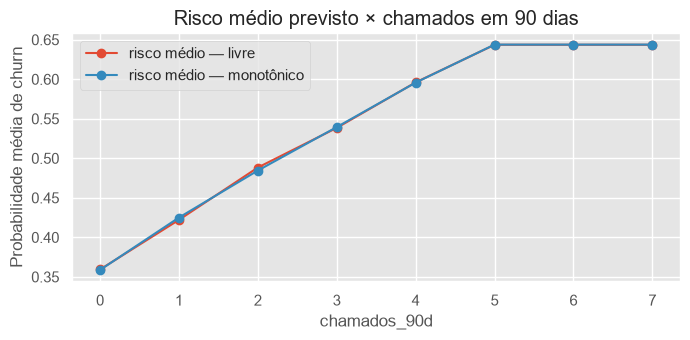

In [41]:
RESTRICOES = {"chamados_90d": 1, "atrasos_6m": 1, "tipo_contrato": -1, "tempo_cliente_meses": -1}

xgb_monotonico = clone(XGB_FINAL.named_steps["modelo"]).set_params(monotone_constraints=RESTRICOES)
resultado_h5 = comparar_variantes({
    "XGBoost — livre (atual)": montar_pipeline(MODELOS_BASE["XGBoost"]()),
    "XGBoost — monotônico": montar_pipeline(xgb_monotonico),
}, referencia="XGBoost — livre (atual)")
display(resultado_h5)

# Verificação: risco médio previsto ao variar só os chamados, com o modelo monotônico
modelo_mono = montar_pipeline(clone(xgb_monotonico)).fit(X_treino, y_treino)
modelo_livre = clone(XGB_FINAL).fit(X_treino, y_treino)
efeito_chamados = []
for chamados in range(0, 8):
    X_var = X_treino.copy()
    X_var["chamados_90d"] = chamados
    efeito_chamados.append({"chamados_90d": chamados,
                            "risco médio — livre": modelo_livre.predict_proba(X_var)[:, 1].mean(),
                            "risco médio — monotônico": modelo_mono.predict_proba(X_var)[:, 1].mean()})
efeito_chamados = pd.DataFrame(efeito_chamados).set_index("chamados_90d")
efeito_chamados.plot(marker="o", figsize=(7, 3.5), title="Risco médio previsto × chamados em 90 dias")
plt.ylabel("Probabilidade média de churn")
plt.tight_layout()
plt.show()

### 8.6 Resumo das hipóteses

In [42]:
resumo_hipoteses = pd.concat(tabelas_h2 + tabelas_h3 + tabelas_h4 + [resultado_h5])
resumo_hipoteses = resumo_hipoteses[~resumo_hipoteses["adotar?"].eq("(atual)")]
print(f"Variantes testadas: {len(resumo_hipoteses)} | adotadas (ganho de PR-AUC ≥ {GANHO_MINIMO}): "
      f"{int(resumo_hipoteses['adotar?'].eq('sim').sum())}")
display(resumo_hipoteses[["PR-AUC (val)", "Δ PR-AUC vs atual", "precisão c/ recall 80%", "adotar?"]])

Variantes testadas: 9 | adotadas (ganho de PR-AUC ≥ 0.01): 0


,PR-AUC (val),Δ PR-AUC vs atual,precisão c/ recall 80%,adotar?
Regressão logística — one-hot,0.6709,0.0006,0.5524,não
AD — one-hot,0.6106,-0.0071,0.5092,não
XGBoost — one-hot,0.6631,-0.0029,0.5453,não
AD — ausentes nativos,0.6166,-0.0010,0.5135,não
XGBoost — ausentes nativos,0.6622,-0.0037,0.5434,não
Regressão logística — + 3 derivados,0.6699,-0.0004,0.5490,não
AD — + 3 derivados,0.6102,-0.0075,0.4997,não
XGBoost — + 3 derivados,0.6631,-0.0029,0.5484,não
XGBoost — monotônico,0.6680,0.0021,0.5498,não


## 9. Avaliação final no conjunto de teste

Esta é a **primeira e única vez** que o teste (1.497 clientes, 30%) é usado. Todas as escolhas foram feitas antes, por validação cruzada no treino:

| Modelo | Hiperparâmetros | Limiar |
|---|---|---|
| Regressão logística | padronização + `class_weight="balanced"` | escolhido para recall de 80% (OOF) |
| Árvore de Decisão | melhor pré-poda (seção 5.2) | idem |
| Árvore de Decisão pós-podada | melhor `ccp_alpha` (seção 5.3), para referência | idem |
| XGBoost | melhor busca (seção 6.6) | idem |

Os modelos são ajustados no treino completo (70%), e o limiar escolhido no treino é aplicado sem alteração no teste.

In [43]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, confusion_matrix
)

MODELOS_TESTE = {
    "Regressão logística": (clone(MODELOS_FINAIS["Regressão logística"]).fit(X_treino, y_treino), LIMIAR_LR),
    NOME_AD_FINAL: (AD_FINAL, LIMIAR_AD),
    "AD pós-poda": (ad_pos, LIMIAR_AD_POS),
    NOME_XGB_FINAL: (XGB_FINAL, LIMIAR_XGB),
}


def metricas(y, proba, limiar):
    pred = (proba >= limiar).astype(int)
    return {
        "recall": recall_score(y, pred), "precisão": precision_score(y, pred),
        "F1": f1_score(y, pred), "F2": fbeta_score(y, pred, beta=2),
        "acurácia": accuracy_score(y, pred),
        "ROC-AUC": roc_auc_score(y, proba), "PR-AUC": average_precision_score(y, proba),
    }


PROBA_TESTE, PROBA_TREINO, linhas_teste, linhas_gap = {}, {}, [], []
for nome, (modelo, limiar) in MODELOS_TESTE.items():
    PROBA_TESTE[nome] = modelo.predict_proba(X_teste)[:, 1]
    PROBA_TREINO[nome] = modelo.predict_proba(X_treino)[:, 1]
    m_teste = metricas(y_teste, PROBA_TESTE[nome], limiar)
    m_treino = metricas(y_treino, PROBA_TREINO[nome], limiar)
    linhas_teste.append({"modelo": nome, "limiar": limiar, **m_teste})
    linhas_gap.append({"modelo": nome,
                       "recall treino": m_treino["recall"], "recall teste": m_teste["recall"],
                       "gap recall": m_treino["recall"] - m_teste["recall"],
                       "acurácia treino": m_treino["acurácia"], "acurácia teste": m_teste["acurácia"],
                       "gap acurácia": m_treino["acurácia"] - m_teste["acurácia"],
                       "PR-AUC treino": m_treino["PR-AUC"], "PR-AUC teste": m_teste["PR-AUC"]})

RESULTADO_TESTE = pd.DataFrame(linhas_teste).set_index("modelo")
print("--- MÉTRICAS NO TESTE (LIMIAR ESCOLHIDO NO TREINO) ---")
display(RESULTADO_TESTE.round(3))
print("--- GAP TREINO (70%) × TESTE (30%) ---")
display(pd.DataFrame(linhas_gap).set_index("modelo").round(3))

--- MÉTRICAS NO TESTE (LIMIAR ESCOLHIDO NO TREINO) ---


,limiar,recall,precisão,F1,F2,acurácia,ROC-AUC,PR-AUC
modelo,,,,,,,,
Regressão logística,0.435,0.780,0.555,0.648,0.721,0.699,0.801,0.694
AD pré-poda,0.425,0.737,0.509,0.602,0.676,0.654,0.752,0.622
AD pós-poda,0.449,0.761,0.490,0.596,0.686,0.634,0.735,0.581
XGB GridSearch,0.442,0.774,0.546,0.641,0.715,0.691,0.794,0.682


--- GAP TREINO (70%) × TESTE (30%) ---


,recall treino,recall teste,gap recall,acurácia treino,acurácia teste,gap acurácia,PR-AUC treino,PR-AUC teste
modelo,,,,,,,,
Regressão logística,0.803,0.780,0.023,0.698,0.699,-0.001,0.671,0.694
AD pré-poda,0.809,0.737,0.072,0.700,0.654,0.046,0.679,0.622
AD pós-poda,0.839,0.761,0.077,0.675,0.634,0.041,0.636,0.581
XGB GridSearch,0.825,0.774,0.051,0.710,0.691,0.019,0.694,0.682


### 9.1 Matrizes de confusão

Linhas = classe real; colunas = classe prevista. O canto inferior esquerdo são os **falsos negativos** (churners não detectados), o erro que mais queremos evitar.

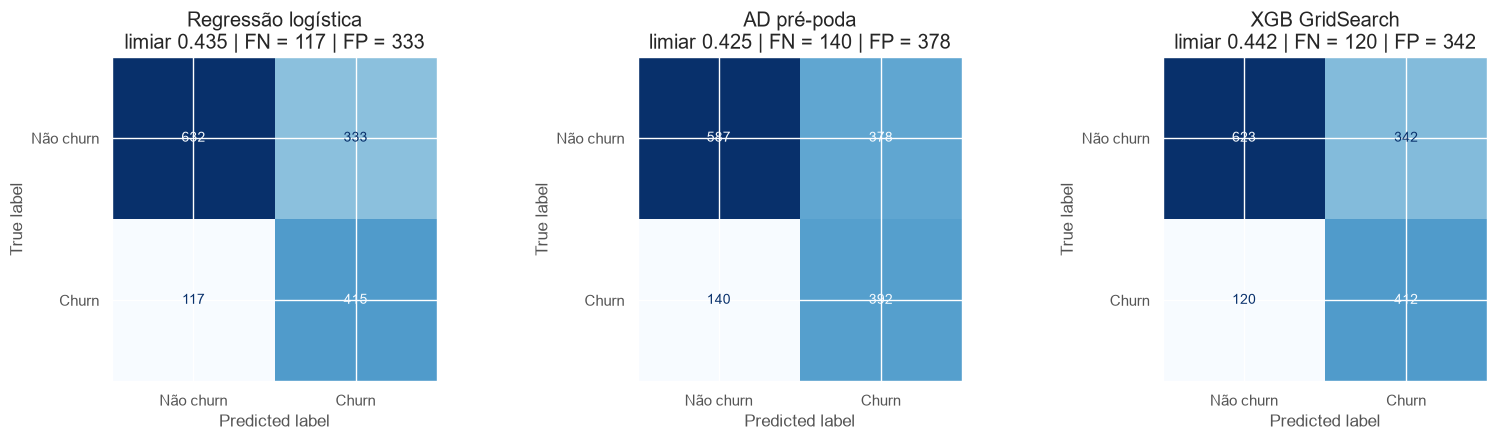

In [44]:
nomes_principais = ["Regressão logística", NOME_AD_FINAL, NOME_XGB_FINAL]
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))
for eixo, nome in zip(eixos, nomes_principais):
    _, limiar = MODELOS_TESTE[nome]
    pred = (PROBA_TESTE[nome] >= limiar).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_teste, pred), display_labels=["Não churn", "Churn"]).plot(
        ax=eixo, cmap="Blues", colorbar=False)
    tn, fp, fn, tp = confusion_matrix(y_teste, pred).ravel()
    eixo.set_title(f"{nome}\nlimiar {limiar:.3f} | FN = {fn} | FP = {fp}")
plt.tight_layout()
plt.show()

### 9.2 Curvas ROC e precisão-recall

A curva ROC mostra a separação global entre as classes. A curva precisão-recall é mais informativa com classes desbalanceadas: mostra quanta precisão se perde para cada ganho de recall. O ponto marcado é o limiar escolhido de cada modelo.

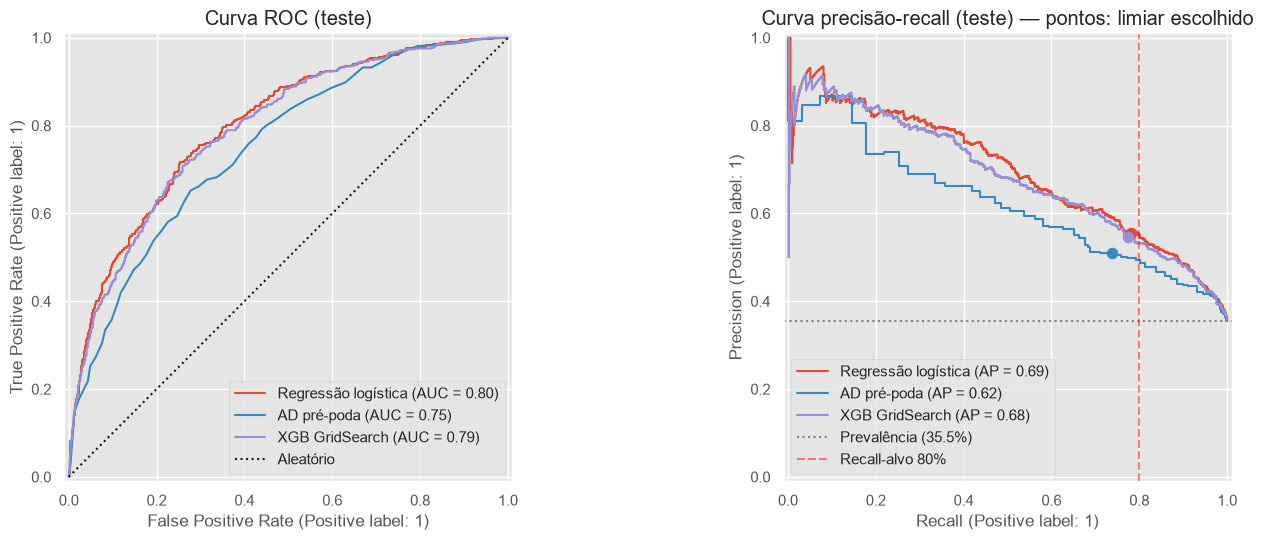

In [45]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))
for nome in nomes_principais:
    RocCurveDisplay.from_predictions(y_teste, PROBA_TESTE[nome], ax=eixos[0], name=nome)
    PrecisionRecallDisplay.from_predictions(y_teste, PROBA_TESTE[nome], ax=eixos[1], name=nome)
    _, limiar = MODELOS_TESTE[nome]
    pred = (PROBA_TESTE[nome] >= limiar).astype(int)
    eixos[1].scatter(recall_score(y_teste, pred), precision_score(y_teste, pred), s=60, zorder=5)
eixos[0].plot([0, 1], [0, 1], "k:", label="Aleatório")
eixos[0].set_title("Curva ROC (teste)")
eixos[0].legend(loc="lower right")
eixos[1].axhline(y_teste.mean(), color="gray", linestyle=":", label=f"Prevalência ({y_teste.mean():.1%})")
eixos[1].axvline(RECALL_ALVO, color="red", linestyle="--", alpha=0.5, label="Recall-alvo 80%")
eixos[1].set_title("Curva precisão-recall (teste) — pontos: limiar escolhido")
eixos[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

### 9.3 Incerteza das métricas no teste (bootstrap)

O teste tem 1.497 clientes, e uma diferença de 0,01 pode ser acaso. Reamostramos o teste com reposição 2.000 vezes para obter **intervalos de confiança de 95%** de cada métrica e da diferença entre XGBoost e regressão logística (amostras pareadas: os mesmos clientes nos dois modelos).

In [46]:
N_BOOT = 2000
gerador = np.random.default_rng(SEED)
y_teste_np = y_teste.to_numpy()
amostras = [gerador.integers(0, len(y_teste_np), len(y_teste_np)) for _ in range(N_BOOT)]


def bootstrap(nome):
    _, limiar = MODELOS_TESTE[nome]
    proba = PROBA_TESTE[nome]
    valores = {"recall": [], "precisão": [], "ROC-AUC": [], "PR-AUC": []}
    for idx in amostras:
        y_b, p_b = y_teste_np[idx], proba[idx]
        pred = (p_b >= limiar).astype(int)
        valores["recall"].append(recall_score(y_b, pred))
        valores["precisão"].append(precision_score(y_b, pred))
        valores["ROC-AUC"].append(roc_auc_score(y_b, p_b))
        valores["PR-AUC"].append(average_precision_score(y_b, p_b))
    return {k: np.array(v) for k, v in valores.items()}


BOOT = {nome: bootstrap(nome) for nome in nomes_principais}
intervalos = pd.DataFrame({
    nome: {m: f"{RESULTADO_TESTE.loc[nome, m]:.3f} [{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
           for m, v in valores.items()}
    for nome, valores in BOOT.items()
}).T
print("--- MÉTRICAS NO TESTE COM IC 95% (BOOTSTRAP) ---")
display(intervalos)

diferencas = []
for metrica in ["ROC-AUC", "PR-AUC", "precisão", "recall"]:
    for outro in ["Regressão logística", NOME_AD_FINAL]:
        d = BOOT[NOME_XGB_FINAL][metrica] - BOOT[outro][metrica]
        diferencas.append({"métrica": metrica, "comparação": f"XGBoost − {outro}",
                           "Δ médio": d.mean(), "IC 2,5%": np.percentile(d, 2.5), "IC 97,5%": np.percentile(d, 97.5),
                           "diferença clara?": "sim" if (np.percentile(d, 2.5) > 0 or np.percentile(d, 97.5) < 0) else "não"})
print("--- DIFERENÇAS PAREADAS NO TESTE ---")
display(pd.DataFrame(diferencas).set_index(["métrica", "comparação"]).round(3))

--- MÉTRICAS NO TESTE COM IC 95% (BOOTSTRAP) ---


,recall,precisão,ROC-AUC,PR-AUC
Regressão logística,"0.780 [0.745, 0.815]","0.555 [0.518, 0.592]","0.801 [0.778, 0.823]","0.694 [0.651, 0.735]"
AD pré-poda,"0.737 [0.699, 0.774]","0.509 [0.473, 0.545]","0.752 [0.727, 0.777]","0.622 [0.580, 0.665]"
XGB GridSearch,"0.774 [0.739, 0.810]","0.546 [0.511, 0.582]","0.794 [0.770, 0.817]","0.682 [0.641, 0.723]"


--- DIFERENÇAS PAREADAS NO TESTE ---


Δ médio  IC 2,5%  IC 97,5% diferença clara?
métrica  comparação                                                                
ROC-AUC  XGBoost − Regressão logística   -0.007   -0.013    -0.001              sim
         XGBoost − AD pré-poda            0.042    0.028     0.055              sim
PR-AUC   XGBoost − Regressão logística   -0.011   -0.023     0.001              não
         XGBoost − AD pré-poda            0.062    0.039     0.085              sim
precisão XGBoost − Regressão logística   -0.009   -0.022     0.004              não
         XGBoost − AD pré-poda            0.037    0.017     0.058              sim
recall   XGBoost − Regressão logística   -0.006   -0.023     0.011              não
         XGBoost − AD pré-poda            0.038    0.007     0.069              sim

### 9.4 Análise de custo: qual limiar dá mais retorno?

O recall-alvo de 80% é uma escolha de negócio. Para ilustrar como ela poderia ser feita com base em valores, montamos um **cenário hipotético** (os valores não vêm da base e devem ser substituídos pelos reais da operadora):

- **Valor de um cliente retido:** 12 mensalidades medianas (receita de um ano).
- **Custo da ação de retenção:** meia mensalidade mediana (desconto ou bônus oferecido a cada cliente acionado).
- **Taxa de sucesso da ação:** 30% dos churners acionados permanecem.

Lucro da campanha = (verdadeiros positivos × 30% × valor do cliente) − (todos os acionados × custo da ação).

O limiar que maximiza o lucro é escolhido com as probabilidades **out-of-fold do treino** e só depois aplicado ao teste, como os demais limiares.

Mensalidade mediana (treino): R$ 85.65 | valor do cliente: R$ 1027.80 | custo da ação: R$ 42.83 | sucesso: 30%


--- CENÁRIOS NO TESTE (XGB GridSearch, 1497 clientes) ---


,clientes acionados,churners alcançados,recall,lucro no teste (R$)
cenário,,,,
Ninguém é acionado,0,0,0.000,0.000
Todos são acionados,1497,532,1.000,99927.855
Limiar do recall 80% (0.442),754,412,0.774,94746.030
Limiar de lucro máximo (0.230),1112,497,0.934,105623.580


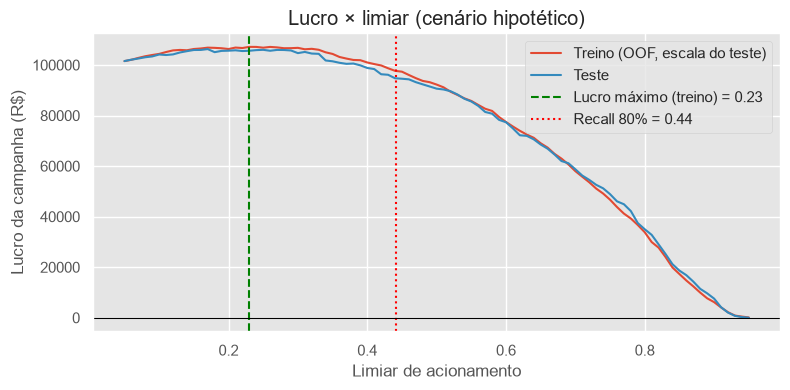

--- SENSIBILIDADE À TAXA DE SUCESSO DA RETENÇÃO ---


,limiar ótimo (treino),recall no teste,lucro no teste (R$)
taxa de sucesso da retenção,,,
10%,0.58,0.630,11862.525
20%,0.32,0.889,55903.755
30%,0.23,0.934,105623.580
50%,0.12,0.976,210870.300


In [47]:
MENSALIDADE_MEDIANA = X_treino["mensalidade_rs"].median()
VALOR_CLIENTE = 12 * MENSALIDADE_MEDIANA
CUSTO_ACAO = 0.5 * MENSALIDADE_MEDIANA
TAXA_SUCESSO = 0.30
print(f"Mensalidade mediana (treino): R$ {MENSALIDADE_MEDIANA:.2f} | valor do cliente: R$ {VALOR_CLIENTE:.2f} | "
      f"custo da ação: R$ {CUSTO_ACAO:.2f} | sucesso: {TAXA_SUCESSO:.0%}")


def lucro(y, proba, limiar):
    acionados = proba >= limiar
    vp = (acionados & (y == 1)).sum()
    return vp * TAXA_SUCESSO * VALOR_CLIENTE - acionados.sum() * CUSTO_ACAO


grade_limiares = np.linspace(0.05, 0.95, 91)
nome_custo = NOME_XGB_FINAL
proba_oof = cross_val_predict(clone(XGB_FINAL), X_treino, y_treino, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
lucros_oof = np.array([lucro(y_treino.to_numpy(), proba_oof, l) for l in grade_limiares])
LIMIAR_CUSTO = grade_limiares[np.argmax(lucros_oof)]
lucros_teste = np.array([lucro(y_teste_np, PROBA_TESTE[nome_custo], l) for l in grade_limiares])

cenarios = {
    "Ninguém é acionado": np.inf,
    "Todos são acionados": 0.0,
    f"Limiar do recall 80% ({LIMIAR_XGB:.3f})": LIMIAR_XGB,
    f"Limiar de lucro máximo ({LIMIAR_CUSTO:.3f})": LIMIAR_CUSTO,
}
tabela_custo = []
for cenario, limiar in cenarios.items():
    acionados = PROBA_TESTE[nome_custo] >= limiar
    tabela_custo.append({
        "cenário": cenario, "clientes acionados": int(acionados.sum()),
        "churners alcançados": int((acionados & (y_teste_np == 1)).sum()),
        "recall": (acionados & (y_teste_np == 1)).sum() / y_teste_np.sum(),
        "lucro no teste (R$)": lucro(y_teste_np, PROBA_TESTE[nome_custo], limiar),
    })
print(f"--- CENÁRIOS NO TESTE ({nome_custo}, {len(y_teste_np)} clientes) ---")
display(pd.DataFrame(tabela_custo).set_index("cenário").round(3))

fig, eixo = plt.subplots(figsize=(8, 4))
eixo.plot(grade_limiares, lucros_oof * len(y_teste_np) / len(y_treino), label="Treino (OOF, escala do teste)")
eixo.plot(grade_limiares, lucros_teste, label="Teste")
eixo.axvline(LIMIAR_CUSTO, color="green", linestyle="--", label=f"Lucro máximo (treino) = {LIMIAR_CUSTO:.2f}")
eixo.axvline(LIMIAR_XGB, color="red", linestyle=":", label=f"Recall 80% = {LIMIAR_XGB:.2f}")
eixo.axhline(0, color="black", linewidth=0.8)
eixo.set_xlabel("Limiar de acionamento")
eixo.set_ylabel("Lucro da campanha (R$)")
eixo.set_title("Lucro × limiar (cenário hipotético)")
eixo.legend()
plt.tight_layout()
plt.show()

sensibilidade = []
for sucesso in [0.1, 0.2, 0.3, 0.5]:
    TAXA_SUCESSO_ORIG, TAXA_SUCESSO = TAXA_SUCESSO, sucesso
    l_oof = np.array([lucro(y_treino.to_numpy(), proba_oof, l) for l in grade_limiares])
    limiar_otimo = grade_limiares[np.argmax(l_oof)]
    pred = PROBA_TESTE[nome_custo] >= limiar_otimo
    sensibilidade.append({"taxa de sucesso da retenção": f"{sucesso:.0%}", "limiar ótimo (treino)": limiar_otimo,
                          "recall no teste": (pred & (y_teste_np == 1)).sum() / y_teste_np.sum(),
                          "lucro no teste (R$)": lucro(y_teste_np, PROBA_TESTE[nome_custo], limiar_otimo)})
    TAXA_SUCESSO = TAXA_SUCESSO_ORIG
print("--- SENSIBILIDADE À TAXA DE SUCESSO DA RETENÇÃO ---")
display(pd.DataFrame(sensibilidade).set_index("taxa de sucesso da retenção").round(3))

### 9.5 Conclusões da avaliação final

**Resultados no teste** (1.497 clientes, limiar escolhido no treino para recall de 80%):

| Modelo | Recall | Precisão | F1 | ROC-AUC | PR-AUC | Gap recall treino-teste |
|---|---|---|---|---|---|---|
| Regressão logística | **0,780** | **0,555** | **0,648** | **0,801** | **0,694** | 0,023 |
| XGBoost (GridSearch) | 0,774 | 0,546 | 0,641 | 0,794 | 0,682 | 0,051 |
| Árvore de Decisão (pré-poda) | 0,737 | 0,509 | 0,602 | 0,752 | 0,622 | 0,072 |
| Árvore de Decisão (pós-poda) | 0,761 | 0,490 | 0,596 | 0,735 | 0,581 | 0,077 |

- **O teste confirmou o que a validação cruzada indicava.** Os limiares escolhidos no treino entregaram recall de 74–78% no teste, perto do alvo de 80%, e as métricas ficaram dentro da faixa observada na validação. Não há sinal de overfitting relevante em nenhum modelo ajustado (gaps de acurácia ≤ 0,05).
- **O XGBoost supera com folga a Árvore de Decisão** em todas as métricas, com diferença clara no bootstrap (ex.: +0,06 de PR-AUC e +0,04 de precisão). O XGBoost pega 4 churners a mais em cada 100 com menos alarmes falsos.
- **A regressão logística empata ou supera levemente o XGBoost.** Em PR-AUC, precisão e recall, a diferença no teste não é clara (os intervalos de confiança incluem zero), assim como na validação repetida (p = 0,15, seção 8.1). Em ROC-AUC, a logística é ligeiramente melhor (0,007).
- **Na prática:** para cada 100 clientes acionados pelo XGBoost, cerca de 55 realmente cancelariam, contra 35 de uma escolha aleatória. Isso significa encontrar ~77% dos churners acionando metade da base (754 de 1.497 clientes).

**Análise de custo.** No cenário hipotético (ação de retenção barata, R$ 43, e cliente valioso, ~R$ 1.028/ano), o limiar de lucro máximo é bem mais baixo (0,23, recall de 93%) do que o do recall de 80%, porque perder um churner custa muito mais do que acionar um cliente fiel. A análise de sensibilidade mostra que **o limiar ideal depende da eficácia da ação**: com 10% de sucesso, o ótimo sobe para 0,58 (recall de 63%); com 50%, cai para 0,12. Com ações tão baratas, acionar todos já fica perto do ótimo. O modelo passa a valer mais quando a ação é cara ou pouco eficaz, situação em que filtrar os clientes certos faz diferença.

**Hipóteses da equipe (seção 8).** Nenhuma das 9 variantes atingiu o ganho mínimo de 0,01 em PR-AUC:
- one-hot × ordinal: empate para logística e XGBoost; o ordinal é melhor para a árvore (+0,007), o que confirma a decisão da issue #3;
- ausentes nativos × imputação: sem ganho; a imputação simples basta;
- atributos derivados: sem ganho; os modelos já capturam essas interações;
- XGBoost monotônico: **mesmo desempenho** (+0,002), com a garantia de coerência de negócio. É uma opção interessante para produção.

## 10. Conclusões gerais

1. **Preparação dos dados.** Codificação ordinal e variáveis na escala original (issues #3 e #4) deixaram as regras da árvore legíveis sem perda de desempenho, e o protocolo de pipeline + validação cruzada garantiu ausência de vazamento: o teste foi usado uma única vez, na seção 9.
2. **Métrica.** O recall da classe churn é o foco, mas otimizá-lo diretamente (ou pelo F2) só desloca o ponto de corte. Separar a qualidade do modelo (PR-AUC) do ponto de operação (limiar de recall 80% ou de lucro máximo) tornou as comparações justas e as decisões explícitas.
3. **Árvore de Decisão.** A pré-poda (`min_samples_leaf=50`, `max_depth=8`) superou a pós-poda e reduziu o gap de recall de 0,51 (árvore livre) para 0,03. As regras SE-ENTÃO são o principal valor da árvore: **contrato mensal, até 28 meses de casa e 3 ou mais chamados em 90 dias → 74,5% de churn**, e mensalidade alta com atraso eleva o risco a ~90%.
4. **XGBoost.** A busca reduziu o overfitting do modelo padrão (gap de 0,39 → 0,02) e elevou a PR-AUC de 0,61 para 0,67. O Optuna atingiu o mesmo resultado do GridSearch com 6× menos ajustes. O trade-off `n_estimators` × `learning_rate` mostrou a mesma qualidade final com 25 árvores a 0,3 ou 767 a 0,01.
5. **Teto dos dados.** XGBoost e regressão logística empatam (PR-AUC ~0,68–0,69 no teste), o que indica relações em boa parte aditivas e monotônicas entre os 8 atributos e o churn. Ganhos maiores provavelmente dependem de **novos dados** (uso do serviço, reclamações detalhadas, concorrência), não de modelos mais complexos.
6. **Fatores de risco** (consenso entre os modelos): tipo de contrato (mensal), pouco tempo de casa, muitos chamados recentes e atrasos de pagamento. Forma de pagamento não contribui.
7. **Recomendação.** Para **explicar** o churn e orientar ações, usar as regras da Árvore de Decisão. Para **priorizar** clientes, usar o XGBoost (preferencialmente a versão monotônica) ou a regressão logística, que tem desempenho equivalente e é mais simples. O limiar deve ser definido pelo custo real da ação de retenção.